<img src="https://images.seeklogo.com/logo-png/28/1/u-cayetano-heredia-logo-png_seeklogo-289967.png"
     alt="LOGO UPCH" width="250" align="right">

<br>

<h1><font color="#7F000E" size="5">UNIVERSIDAD PERUANA CAYETANO HEREDIA</font></h1>

<h1><font color="#7F000E" size="6">SEÑALES BIOMÉDICAS</font></h1>

<h1><font color="#7F000E" size="4">LABORATORIO 10 — SOLUCIONARIO: resultados explicados y respuestas</font></h1>

<br>

<div style="text-align:right">
  <font color="#7F000E" size="3">Ing. Alexander Valdez Portocarrero</font><br>
  <font color="#7F000E" size="3">Curso: Introducción a las Señales Biomédicas</font><br>
  <font color="#7F000E" size="3">Registros: BASELINEBRAZO.txt y PRUEBABRAZO1.txt (BITalino, 23/10/2026)</font><br>
</div>

**Adaptación del Laboratorio 10** — EMG real. Se mantiene la estructura original (93 celdas), las simulaciones, fórmulas, actividades y código de análisis. Los resultados y respuestas experimentales se actualizaron usando los datos reales `Fuerte_emg (2).txt` (sensor EMGBITREV, A1, 1000 Hz, 10 bits; 291 600 muestras).

**Diseño de esta adaptación:** PRUEBA = registro completo (291.6 s); BASELINE = primeros 15 s del registro, usados como referencia de baja actividad. Son dos conjuntos de datos de una misma toma. La PRUEBA incluye el tramo usado como BASELINE: las comparaciones no son pruebas independientes.

**Resultados principales de la ejecución comprobada**

| Indicador | Resultado con nuestra señal |
|---|---|
| Adquisición | 04/09/2026, EMGBITREV, canal A1, 1000 Hz, ADC 10 bits |
| BASELINE (tramo 0–15 s) / PRUEBA (total) | 15 000 muestras / 291 600 muestras |
| Rango ADC BASELINE / PRUEBA | 473–539 / 0–1022 |
| Resolución del EMG según la fórmula empleada | 3.19 µV/cuenta |
| Saturación (0 o 1023) / incluyendo 1022 | 548 (0.188 %) / 867 (0.297 %) |
| RMS filtrado BASELINE / PRUEBA | 4.16 µV / 199.66 µV |
| Umbral reposo intra-registro; activaciones detectadas | 3.6 µV; 41 intervalos automáticos |
| Ventanas de 250 ms (50 % solapadas) | 2331 (1200 reposo, 1004 contracción, 127 transición) |
| Fisher más alto | MNF: 4.07; P_150_450: 4.01; MDF: 3.75 |
| Exactitud balanceada LDA / SVM, 15 características | 0.892 / 0.892 (GroupKFold) |
| Exactitud balanceada CNN / umbral RMS | 0.870 ± 0.091 / 0.945 ± 0.009 |
| Ejercicio de fatiga | 31 intervalos válidos; correlaciones no significativas |

**Limitaciones:** las etiquetas reposo/contracción se calculan a partir de la propia envolvente EMG y **no son etiquetas experimentales independientes**. Parte de los 41 intervalos detectados son de amplitud muy pequeña, por lo que no todos deben interpretarse como contracciones voluntarias reales. Los resultados de clasificación evalúan la separación de etiquetas derivadas de la misma señal, no el reconocimiento validado de gestos distintos. La fatiga se aborda como análisis exploratorio, sin fuerza controlada ni anotaciones externas.

- **Explicación:** interpretación de la salida inmediatamente anterior.
- **Respuesta:** contestación a las preguntas y ejercicios del laboratorio.
- **Verificación adicional:** comprobaciones del notebook original.

**Para repetir en Colab:** cargar `Fuerte_emg (2).txt`, ejecutar las celdas en orden. Las cifras impresas y figuras se generaron con esta adquisición.


## Pregunta guía del laboratorio

> **¿Cómo convierte un dispositivo la actividad eléctrica de un músculo en números que puede entender?**

Una prótesis mioeléctrica, un exoesqueleto de rehabilitación o un sistema que detecta fatiga en un trabajador **no "miran" la señal cruda**: la resumen en un conjunto pequeño de números llamados **características** (*features*). Elegir y calcular bien esas características es, muchas veces, más importante que el clasificador que viene después.

### Objetivos de aprendizaje
1. Explicar el **origen fisiológico** de la sEMG y sus rangos típicos de amplitud y frecuencia.
2. **Convertir, filtrar y evaluar la calidad** de una señal real adquirida con BITalino.
3. **Segmentar** la señal en ventanas y **etiquetar** automáticamente reposo y contracción.
4. Calcular e interpretar características **temporales, estadísticas y espectrales**.
5. Construir una **matriz de características** y entrenar un clasificador **sin fuga entre ventanas de un mismo grupo**.
6. Entender cómo una **CNN** aprende características a partir del **espectrograma (STFT)** y compararla con el enfoque clásico.

### Agenda (120 min)
| Bloque | Tiempo | Tipo |
|---|---|---|
| 0. Introducción y configuración | 5 min | Motivación |
| 1. Fundamentos fisiológicos | 15 min | Teoría + simulación |
| 2. Instrumentación y adquisición | 10 min | Técnica + práctica |
| 3. Preprocesamiento | 15 min | Práctica |
| 4. Segmentación y etiquetado | 10 min | Técnica + práctica |
| 5. Extracción de características clásicas | 25 min | Teoría + práctica |
| 6. Del vector de características al clasificador | 15 min | Práctica |
| 7. Deep learning: espectrograma + CNN | 15 min | Teoría + demo |
| 8. Ejercicios, cierre y referencias | 10 min | Síntesis |

**Datos utilizados:** `Fuerte_emg (2).txt`, grabado con BITalino (EMGBITREV, A1, 1000 Hz). Para seguir el flujo original con BASELINE y PRUEBA, el código extrae 0–15 s de baja actividad del mismo registro como referencia; **no existe un archivo de reposo separado**. La simulación fisiológica del Bloque 1 sí se conserva por su finalidad didáctica; no sustituye los datos reales de los bloques posteriores.


## 0. Configuración del entorno

Todas las bibliotecas usadas vienen preinstaladas en Google Colab (`numpy`, `scipy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`). No es necesario `opensignalsreader`: escribiremos nuestro propio lector para **entender** el formato del archivo.

In [ ]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.stats import kurtosis, skew

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(42)

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLOR_REPOSO, COLOR_CONTRAC, COLOR_UPCH = "#4C72B0", "#C44E52", "#7F000E"

try:
    from IPython.display import display
except ImportError:
    display = print

print("Entorno listo.")

Entorno listo.


**Explicación:** Esta celda prepara el entorno: importa las bibliotecas, fija una semilla aleatoria (`np.random.seed(42)`) para que la simulación salga igual cada vez y define los colores de las gráficas. El mensaje *"Entorno listo."* confirma que todo se cargó sin errores.

---
# 1. Fundamentos fisiológicos (15 min)

### 1.1 La unidad motora
El músculo no se contrae "en bloque". Se organiza en **unidades motoras (UM)**: una **motoneurona** de la médula espinal y **todas las fibras musculares que inerva**. Cuando la motoneurona dispara, todas sus fibras se despolarizan casi a la vez y producen un **potencial de acción de unidad motora (MUAP)**: una forma de onda bifásica o trifásica de pocos milisegundos.

El sistema nervioso regula la fuerza con dos mecanismos:

| Mecanismo | Qué ocurre | Efecto en la sEMG |
|---|---|---|
| **Reclutamiento** | Se activan más unidades motoras (primero las pequeñas — *principio de Henneman*) | Aumenta la amplitud |
| **Codificación por frecuencia** | Cada UM dispara más rápido (≈ 8 a 30 disparos/s) | Aumenta amplitud y densidad de la señal |

### 1.2 ¿Qué registra un electrodo de superficie?
Un electrodo sobre la piel no ve una UM aislada: ve la **suma espacial y temporal** de los MUAPs de muchas unidades, filtrada por grasa, piel y la propia distancia. El resultado es un **patrón de interferencia** que parece ruido aleatorio, pero cuya **amplitud** y **contenido espectral** codifican información sobre la activación muscular.

> 💡 **Idea clave:** la sEMG es como escuchar un estadio lleno desde afuera. No entiendes a ninguna persona en particular, pero sí sabes si hay pocos o muchos gritando (amplitud) y si las voces son agudas o graves (frecuencia).

### 1.3 Rangos típicos de la sEMG

| Propiedad | Valor típico |
|---|---|
| Amplitud | 0 – 10 mV pico a pico (en reposo: microvoltios) |
| Banda útil | ≈ 10 / 20 – 450 / 500 Hz |
| Energía dominante | ≈ 50 – 150 Hz |
| Distribución de amplitudes | Aproximadamente gaussiana de media cero en contracción sostenida |

Factores que la modifican: grosor del tejido adiposo, posición y distancia entre electrodos, temperatura, **fatiga** (desplaza el espectro a frecuencias más bajas), impedancia piel-electrodo y artefactos.

Veamos cómo surge el patrón de interferencia con una **simulación** simple.

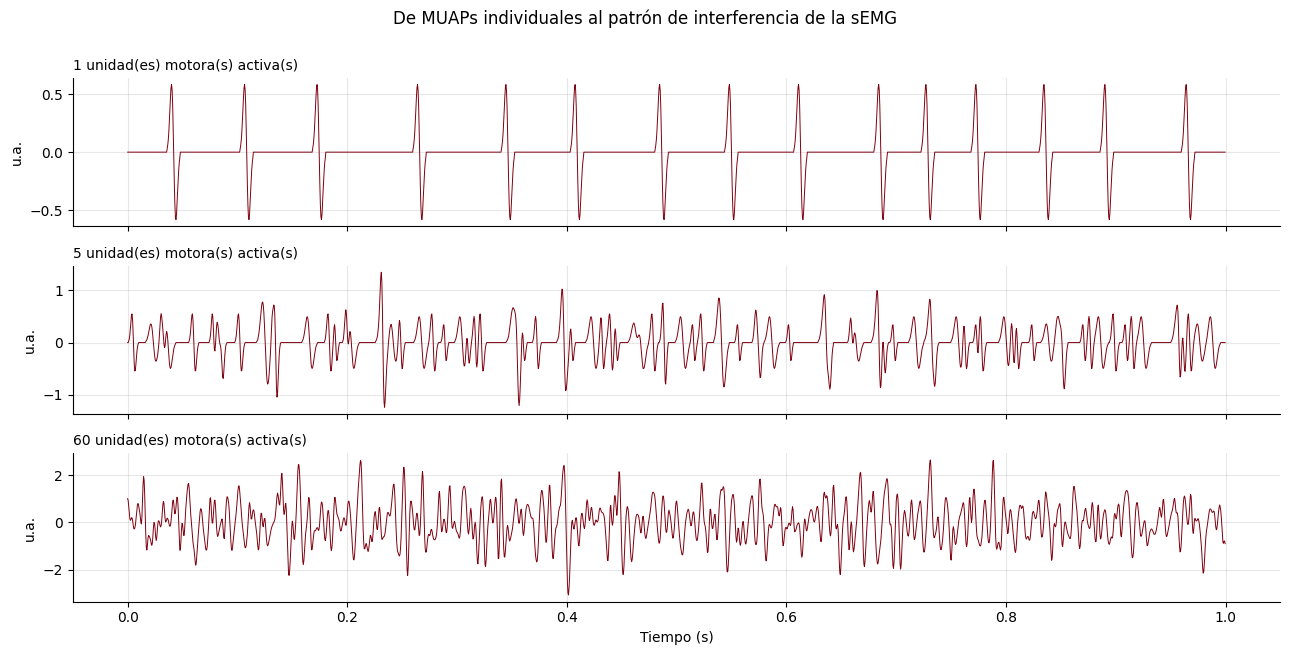

In [ ]:
# Simulación didáctica: suma de trenes de MUAPs
import numpy as np
import matplotlib.pyplot as plt
COLOR_UPCH = globals().get("COLOR_UPCH", "#7F000E")
FS_SIM = 2000
t_sim = np.arange(0, 1.0, 1/FS_SIM)

def muap(duracion_ms=10, fs=FS_SIM):
    # Forma bifásica tipo "derivada de gaussiana" (modelo simplificado de MUAP)
    tt = np.arange(-duracion_ms/2, duracion_ms/2, 1000/fs) / 1000
    s = duracion_ms / 1000 / 6
    return -tt / s * np.exp(-tt**2 / (2*s**2))

def tren_um(fr_hz, amplitud, dur_ms, fs=FS_SIM, n=len(t_sim)):
    # Una unidad motora disparando a ~fr_hz con variabilidad del 20 % entre disparos
    x = np.zeros(n); k = np.random.uniform(0, 1/fr_hz)
    while k < n/fs:
        x[int(k*fs)] = 1
        k += np.random.normal(1/fr_hz, 0.2/fr_hz)
    return amplitud * np.convolve(x, muap(dur_ms, fs), mode="same")

fig, ax = plt.subplots(3, 1, figsize=(13, 6.5), sharex=True)
for a, n_um in zip(ax, [1, 5, 60]):
    total = sum(tren_um(np.random.uniform(8, 25), np.random.uniform(0.2, 1.0),
                        np.random.uniform(6, 14)) for _ in range(n_um))
    a.plot(t_sim, total, lw=0.7, color=COLOR_UPCH)
    a.set_title(f"{n_um} unidad(es) motora(s) activa(s)", loc="left", fontsize=10)
    a.set_ylabel("u.a.")
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("De MUAPs individuales al patrón de interferencia de la sEMG", y=1.0)
plt.tight_layout(); plt.show()

**Explicación:** La simulación construye la sEMG "desde abajo":
1. Se crea la forma de un MUAP (una onda que sube y baja en pocos milisegundos).
2. Cada unidad motora "dispara" ese MUAP entre 8 y 25 veces por segundo, con algo de irregularidad.
3. Se suman los trenes de 1, 5 y 60 unidades motoras.

En la gráfica de arriba (1 UM) se ven picos separados y regulares, uno por cada disparo. En la del medio (5 UM) los picos empiezan a mezclarse. En la de abajo (60 UM) ya no se distingue ningún disparo, la señal parece ruido. Además, el eje vertical crece de una gráfica a otra, más unidades activas producen más amplitud.

> ❓ **Preguntas de verificación**
> 1. Con 1 unidad motora, ¿puedes distinguir cada disparo? ¿Y con 60?
> 2. ¿Qué mecanismo fisiológico representa pasar de 5 a 60 unidades?
> 3. Si la señal con 60 UM "parece ruido", ¿por qué sigue siendo útil? ¿Qué cambia entre las tres gráficas que sí podríamos medir?

**Respuestas**

1. Con 1 UM, sí, cada disparo aparece como un pico aislado, separado del siguiente. Con 60 UM, no, ya que los MUAPs se superponen en el tiempo y forman un patrón continuo (patrón de interferencia) donde ningún disparo individual es reconocible.
2. Representa el reclutamiento, el sistema nervioso activa más unidades motoras para producir más fuerza.
3. Aunque no podamos ver cada disparo, la señal sigue llevando información en propiedades globales que sí se pueden medir. La principal es la amplitud: en la figura, el rango del eje vertical crece al pasar de 1 a 5 y a 60 UM, y eso lo captura una medida como el RMS. También cambia la densidad de la señal (cuántas veces sube y baja por segundo), que capturan medidas como los cruces por cero. Esas propiedades son justamente las características que calcularemos en el Bloque 5.

---
# 2. Instrumentación y adquisición (10 min)

### 2.1 Cadena de adquisición del BITalino
```
Músculo → electrodos Ag/AgCl → amplificador diferencial (G = 1009) → filtro analógico → ADC 10 bits → Bluetooth → OpenSignals (.txt)
```

- **Configuración bipolar / diferencial:** dos electrodos sobre el vientre muscular y uno de referencia en zona eléctricamente neutra (hueso). El amplificador **resta** ambos electrodos: lo que es común a los dos (p. ej., interferencia de la red eléctrica) se cancela (*rechazo en modo común*, CMRR).
- **Colocación:** recomendaciones **SENIAM** — electrodos alineados con las fibras, entre el punto motor y el tendón, con ~20 mm entre centros; piel limpia para reducir la impedancia.

### 2.2 Muestreo y cuantización
- **Frecuencia de muestreo:** el archivo indica **Fs = 1000 Hz** → frecuencia de Nyquist = 500 Hz. Cubre la banda útil de la sEMG.
- **Resolución:** 10 bits → el ADC entrega enteros de **0 a 1023**. El valor ~512 corresponde a 0 V.

### 2.3 Conversión de unidades (hoja técnica del sensor EMG BITalino)

$$
\text{EMG}_{mV} = \frac{\left(\dfrac{ADC}{2^{n}} - \dfrac{1}{2}\right)\cdot V_{CC}}{G_{EMG}} \times 1000,
\qquad V_{CC}=3.3\ \text{V},\ G_{EMG}=1009,\ n = 10
$$

Esto da un rango de medición de aproximadamente **±1.64 mV**. Cualquier actividad mayor **satura** el ADC (se queda pegada en 0 o en 1023).

### 2.4 Fuentes de ruido y artefactos

| Fuente | Característica | Cómo se trata |
|---|---|---|
| Red eléctrica | 60 Hz en Perú (y armónicos) | Diferencial + filtro *notch* |
| Movimiento de electrodos/cables | < 20 Hz, gran amplitud | Pasa-altos ≈ 20 Hz, buena fijación |
| ECG (cerca del tórax) | Picos periódicos ~1 Hz | Pasa-altos, ubicación |
| Ruido térmico/electrónico | Banda ancha, bajo nivel | Se estima con un registro en reposo |
| **Saturación (clipping)** | Señal "aplanada" en el máximo/mínimo del ADC | Prevención (ganancia) y detección |

> 💡 **Idea clave:** ningún filtro digital recupera información que se perdió por saturación. La calidad empieza en la adquisición.

### 2.5 Carga de los archivos

El formato de texto de OpenSignals tiene tres partes:
1. Línea `# OpenSignals Text File Format`.
2. Línea `# {...}` con un **JSON** de metadatos: frecuencia de muestreo, resolución, sensores, nombres de columnas.
3. `# EndOfHeader` y luego los datos en columnas separadas por tabulaciones (`nSeq`, entradas digitales, `A1`...).

Escribimos un lector que **lee los metadatos del propio archivo** en lugar de suponerlos.

**En Colab:** ejecuta la celda siguiente; si los archivos no están en la carpeta, se abrirá un diálogo para subirlos.

In [ ]:
# ÚNICO CAMBIO DE ARCHIVO: usamos nuestra adquisición real.
RUTA_PRUEBA = "Fuerte_emg (2).txt"
EN_COLAB = "google.colab" in sys.modules
if not os.path.isfile(RUTA_PRUEBA) and EN_COLAB:
    from google.colab import files
    print("Sube el archivo original Fuerte_emg (2).txt")
    subidos = files.upload()
    if RUTA_PRUEBA not in subidos and len(subidos) == 1:
        nombre_subido = next(iter(subidos))
        if nombre_subido.lower().endswith(".txt"):
            RUTA_PRUEBA = nombre_subido
if not os.path.isfile(RUTA_PRUEBA):
    raise FileNotFoundError("Falta Fuerte_emg (2).txt. Súbelo antes de continuar.")
USAR_SIMULADA = False
print("Usando señal REAL (BITalino):", RUTA_PRUEBA)


Usando señal REAL (BITalino): Fuerte_emg (2).txt


**Explicación:** Se localiza el archivo `Fuerte_emg (2).txt` en la carpeta de Colab o se solicita su carga. La adquisición utilizada en los bloques experimentales es real, no se debe confundir con la simulación de unidades motoras del Bloque 1. Solo se requiere un archivo de señal.


In [ ]:
def leer_opensignals(ruta, etiqueta_canal="A1"):
    # Lee un TXT de OpenSignals y devuelve (valores ADC del canal, diccionario de metadatos)
    with open(ruta, "r", encoding="utf-8") as f:
        cabecera = [next(f) for _ in range(3)]
    meta = list(json.loads(cabecera[1].lstrip("# ").strip()).values())[0]
    datos = np.loadtxt(ruta, comments="#")
    idx_col = meta["column"].index(etiqueta_canal)
    idx_res = meta["column"].index(etiqueta_canal)
    meta["bits"] = meta["resolution"][idx_res]
    return datos[:, idx_col].astype(float), meta


def simular_registros(fs=1000, n_bits=10):
    # Plan B: genera baseline + prueba con contracciones cada ~3 s (en cuentas ADC)
    rng = np.random.default_rng(0)
    def a_adc(mv):
        adc = (mv / 1000 * 1009 / 3.3 + 0.5) * 2**n_bits
        return np.clip(np.round(adc), 0, 2**n_bits - 1)
    base = 0.006 * rng.standard_normal(69 * fs)
    t = np.arange(63 * fs) / fs
    prueba = 0.025 * rng.standard_normal(len(t))
    for k, ini in enumerate(np.arange(1.5, 61, 3.0)):
        idx = (t >= ini) & (t < ini + 1.2)
        env = np.hanning(idx.sum())
        b, a = signal.butter(2, [40, 200], "bandpass", fs=fs)
        ruido = signal.lfilter(b, a, rng.standard_normal(idx.sum()))
        prueba[idx] += (0.9 - 0.01 * k) * env * ruido / ruido.std() * 0.5
    meta = {"sampling rate": fs, "bits": n_bits, "sensor": ["EMG simulado"], "date": "-", "time": "-"}
    return a_adc(base), dict(meta), a_adc(prueba), dict(meta)


# La guía original usa baseline y prueba separados. Este archivo es una sola adquisición:
# referencia de reposo = primeros 15 segundos de baja actividad del MISMO registro.
# No es una medición basal independiente y no se inventa un segundo archivo.
adc_prueba, meta_prueba = leer_opensignals(RUTA_PRUEBA)
segundos_reposo = 15
adc_base = adc_prueba[:segundos_reposo * int(meta_prueba["sampling rate"])].copy()
meta_base = dict(meta_prueba)
meta_base["time"] = str(meta_prueba.get("time", "")) + " (tramo inicial, no archivo separado)"
RUTA_BASELINE = "Tramo 0–15 s de Fuerte_emg (2).txt"

FS = int(meta_prueba["sampling rate"])
N_BITS = int(meta_prueba["bits"])
assert FS == int(meta_base["sampling rate"]), "Los registros tienen Fs distintas."

for nombre, adc, meta in [("BASELINE", adc_base, meta_base), ("PRUEBA", adc_prueba, meta_prueba)]:
    print(f"{nombre:9s} | sensor: {meta['sensor'][0]:11s} | fecha: {meta['date']} {meta['time']} | "
          f"Fs = {meta['sampling rate']} Hz | {meta['bits']} bits | "
          f"{len(adc):,} muestras = {len(adc)/FS:.1f} s | ADC min/max: {adc.min():.0f}/{adc.max():.0f}")

BASELINE  | sensor: EMGBITREV   | fecha: 2026-9-4 15:8:30.902 (tramo inicial, no archivo separado) | Fs = 1000 Hz | 10 bits | 15,000 muestras = 15.0 s | ADC min/max: 473/539
PRUEBA    | sensor: EMGBITREV   | fecha: 2026-9-4 15:8:30.902 | Fs = 1000 Hz | 10 bits | 291,600 muestras = 291.6 s | ADC min/max: 0/1022


In [ ]:
N_BITS

10

**Explicación de la lectura de metadatos y muestras (señal real).**

- **Sensor:** EMGBITREV, canal A1, 1000 Hz, 10 bits (ADC entre 0 y 1023).
- **BASELINE:** 15 000 muestras = 15.0 s, valores ADC de 473 a 539. Se trata del tramo inicial de baja actividad del mismo registro, no de un archivo independiente.
- **PRUEBA:** 291 600 muestras = 291.6 s, valores ADC de 0 a 1022.
- Fecha/hora de adquisición para ambas variables: 04/09/2026 a las 15:08:30.902, porque provienen de una sola grabación. No hay una separación de cinco minutos entre archivos.

El rango observado (0–1022) aconseja comprobar si existen muestras pegadas a los extremos del ADC. **No se puede afirmar que todo el tramo inicial sea reposo absoluto sin marcas del protocolo.**


Rango medible del sensor: ±1.632 mV
Resolución (1 cuenta ADC): 0.0032 mV = 3.19 µV


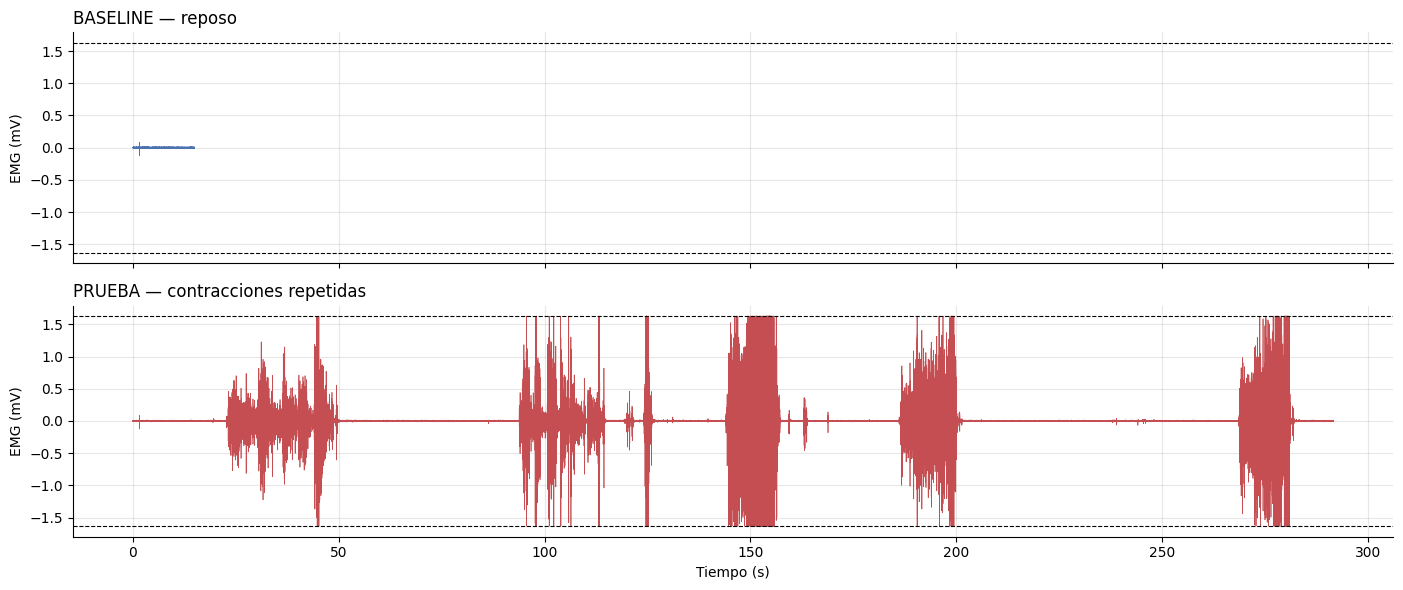

In [ ]:
VCC, G_EMG = 3.3, 1009

def adc_a_mV(adc, n_bits=N_BITS, vcc=VCC, ganancia=G_EMG):
    return ((adc / 2**n_bits) - 0.5) * vcc / ganancia * 1000

emg_base_mV   = adc_a_mV(adc_base)
emg_prueba_mV = adc_a_mV(adc_prueba)
t_base   = np.arange(len(emg_base_mV)) / FS
t_prueba = np.arange(len(emg_prueba_mV)) / FS

rango_max = adc_a_mV(2**N_BITS - 1)
print(f"Rango medible del sensor: ±{rango_max:.3f} mV")
print(f"Resolución (1 cuenta ADC): {adc_a_mV(513) - adc_a_mV(512):.4f} mV = "
      f"{(adc_a_mV(513) - adc_a_mV(512))*1000:.2f} µV")

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True, sharey=True)
ax[0].plot(t_base, emg_base_mV, lw=0.5, color=COLOR_REPOSO)
ax[0].set_title("BASELINE — reposo", loc="left")
ax[1].plot(t_prueba, emg_prueba_mV, lw=0.5, color=COLOR_CONTRAC)
ax[1].set_title("PRUEBA — contracciones repetidas", loc="left")
for a in ax:
    a.axhline(rango_max, ls="--", color="k", lw=0.8); a.axhline(-rango_max, ls="--", color="k", lw=0.8)
    a.set_ylabel("EMG (mV)")
ax[1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

**Explicación de la conversión ADC a milivoltios:** Con la expresión del laboratorio (VCC = 3.3 V, ganancia = 1009, 10 bits), el intervalo medible se aproxima a ±1.632 mV y cada cuenta representa 3.19 µV. El gráfico muestra el tramo inicial BASELINE (0–15 s) y los 291.6 s de PRUEBA; esta última contiene varias ráfagas intensas y lapsos de baja actividad. Algunos valores llegan al límite inferior ADC = 0. El trazado es de una sola grabación, no de sesiones distintas.


### 2.6 Control de calidad: ¿hay saturación?
Con el criterio del laboratorio, una muestra se considera saturada si el ADC es 0 o $2^n-1$. Un valor cercano al extremo, como 1022, se estudia por separado: puede indicar recorte, pero no lo confirma por sí solo. Es importante **cuantificarlo** antes de calcular características, porque recorta los picos y distorsiona sobre todo las medidas sensibles a los extremos (curtosis, varianza).

Saturación BASELINE: 0 muestras (0.000 %)
Saturación PRUEBA  : 548 muestras (0.188 %)


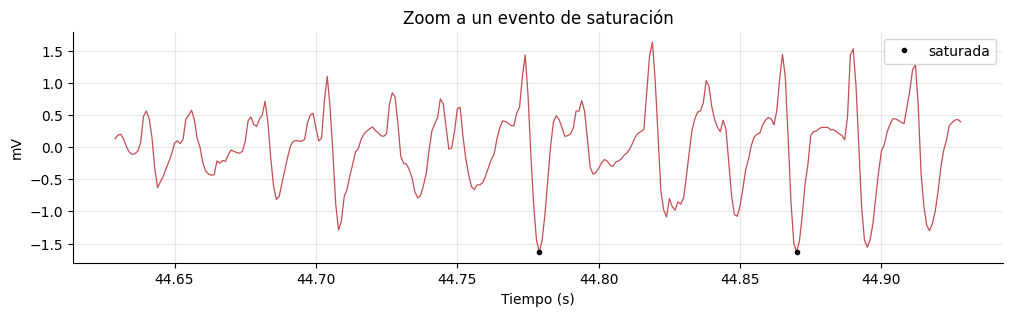

In [ ]:
sat_prueba = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 1)
sat_base   = (adc_base   <= 0) | (adc_base   >= 2**N_BITS - 1)
print(f"Saturación BASELINE: {sat_base.sum()} muestras ({100*sat_base.mean():.3f} %)")
print(f"Saturación PRUEBA  : {sat_prueba.sum()} muestras ({100*sat_prueba.mean():.3f} %)")

if sat_prueba.any():
    i0 = np.flatnonzero(sat_prueba)[0]
    sl = slice(max(0, i0 - 150), i0 + 150)
    plt.figure(figsize=(12, 3))
    plt.plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.9, color=COLOR_CONTRAC)
    plt.plot(t_prueba[sl][sat_prueba[sl]], emg_prueba_mV[sl][sat_prueba[sl]], "ko", ms=3, label="saturada")
    plt.title("Zoom a un evento de saturación"); plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.legend()
    plt.show()

**Explicación: saturación con el criterio del laboratorio.**

- BASELINE (0–15 s): 0 muestras exactamente en 0 o 1023.
- PRUEBA (291.6 s): 548 muestras (0.188 %); todas están en ADC = 0, porque el máximo observado es 1022.
- Las muestras en el límite inferior sugieren recorte de amplitud, especialmente relevante durante actividad intensa. El porcentaje global pequeño no garantiza que las ventanas afectadas estén libres de sesgo.

La celda siguiente examina además la acumulación de valores cercanos al límite superior.


**Comprobación:** los 548 valores ADC=0 proceden de nuestro archivo `Fuerte_emg (2).txt`; no son resultados heredados del notebook original.

🔎 **Verificación adicional — ¿dónde se "pega" realmente el ADC?**

La celda siguiente cuenta cuántas veces aparece cada valor extremo del ADC en la PRUEBA.

In [ ]:

# Verificación adicional: ¿en qué valores se "pega" realmente el ADC?
valores, cuentas = np.unique(adc_prueba, return_counts=True)
print("5 valores ADC más bajos :", [(int(v), int(c)) for v, c in zip(valores[:5], cuentas[:5])])
print("5 valores ADC más altos :", [(int(v), int(c)) for v, c in zip(valores[-5:], cuentas[-5:])])

# Criterio corregido: también se cuenta el valor 1022 (2^n - 2), donde se observa la meseta superior
sat_corr = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 2)
n_win_250 = int(0.25 * FS)
ini_250 = np.arange(0, len(adc_prueba) - n_win_250 + 1, n_win_250 // 2)
print(f"\nCriterio original (0 o 1023)       : {sat_prueba.sum()} muestras ({100*sat_prueba.mean():.3f} %)")
print(f"Criterio corregido (0, 1022 o 1023): {sat_corr.sum()} muestras ({100*sat_corr.mean():.3f} %)")
print(f"Ventanas de 250 ms con saturación (criterio corregido): "
      f"{sum(sat_corr[i:i+n_win_250].any() for i in ini_250)}")


5 valores ADC más bajos : [(0, 548), (2, 2), (3, 2), (4, 1), (5, 4)]
5 valores ADC más altos : [(1018, 1), (1019, 4), (1020, 11), (1021, 18), (1022, 319)]

Criterio original (0 o 1023)       : 548 muestras (0.188 %)
Criterio corregido (0, 1022 o 1023): 867 muestras (0.297 %)
Ventanas de 250 ms con saturación (criterio corregido): 158


**Resultado de la verificación de extremos del ADC.**

- Aparecen 548 muestras en ADC = 0 y 319 en ADC = 1022; el valor 1023 no aparece.
- Criterio original de saturación (**0 o 1023**): 548 muestras, 0.188 %.
- Criterio conservador (**0, 1022 o 1023**): 867 muestras, 0.297 %; este criterio señala 158 ventanas de 250 ms.

La concentración de muestras en 1022 es compatible con un límite superior efectivo, pero por sí sola no demuestra cuál es el techo físico del ADC. Por ello, el segundo criterio se presenta como control de calidad conservador, no como una corrección confirmada del hardware.


**Interpretación:** 548 y 867 se refieren a la misma señal analizada con criterios distintos. El segundo total añade 319 muestras en ADC=1022; se trata de un análisis de sensibilidad, no de 319 saturaciones confirmadas.

> ❓ **Preguntas de verificación**
> 1. ¿Qué porcentaje de muestras está saturado? ¿Te parece aceptable?
> 2. ¿Qué cambiarías en la adquisición para evitarlo?
> 3. ¿Por qué el baseline sirve como "registro de ruido" del sistema?

**Respuestas con nuestra adquisición**

1. Con el criterio de extremos del laboratorio (ADC = 0 o 1023) hay 548/291 600 = 0.188 % de muestras saturadas. Considerando también el máximo observado ADC = 1022 hay 867/291 600 = 0.297 % potencialmente afectadas. Aunque las fracciones globales son pequeñas, la saturación puede alterar la amplitud y curtosis de ventanas durante contracciones.
2. Reducir la intensidad solicitada o utilizar un sistema con mayor rango dinámico; revisar colocación/contacto de electrodos y movimiento de cables. La ganancia especificada para el sensor usado en la fórmula es fija; el filtrado digital no recupera muestras recortadas.
3. Un tramo de reposo permite aproximar el ruido de adquisición y fijar umbrales. Aquí se utilizó 0–15 s de la misma grabación, cuyo RMS después de filtrar fue **4.16 µV**. Es una referencia práctica, pero no un registro de ruido separado ni plenamente validado; puede contener actividad o artefactos.


---
# 3. Preprocesamiento (15 min)

### 3.1 ¿Qué queremos eliminar?
1. **Componente continua (offset)** y derivas lentas → el pasa-altos lo resuelve.
2. **Artefactos de movimiento** (< 20 Hz).
3. **Ruido de alta frecuencia** por encima de la banda útil.
4. **Interferencia de 60 Hz** de la red eléctrica.

### 3.2 Diseño de filtros
- **Pasa-banda Butterworth 20–450 Hz, orden 4:** respuesta plana en la banda de paso. Se implementa en forma **SOS** (*second-order sections*) por estabilidad numérica.
- **Notch IIR en 60 Hz, Q = 30:** elimina una banda angosta (~2 Hz) alrededor de 60 Hz.
- **Filtrado de fase cero (`sosfiltfilt` / `filtfilt`):** filtra hacia adelante y hacia atrás, sin desfase. Válido para análisis **offline**; un sistema en tiempo real (prótesis) usaría filtros causales.

> ⚠️ Condición obligatoria: $0 < f_{baja} < f_{alta} < F_s/2$.

Antes de filtrar, miremos el **espectro** (densidad espectral de potencia, PSD) estimado con el **método de Welch**, que promedia periodogramas de segmentos solapados y da una estimación más estable que una sola FFT.

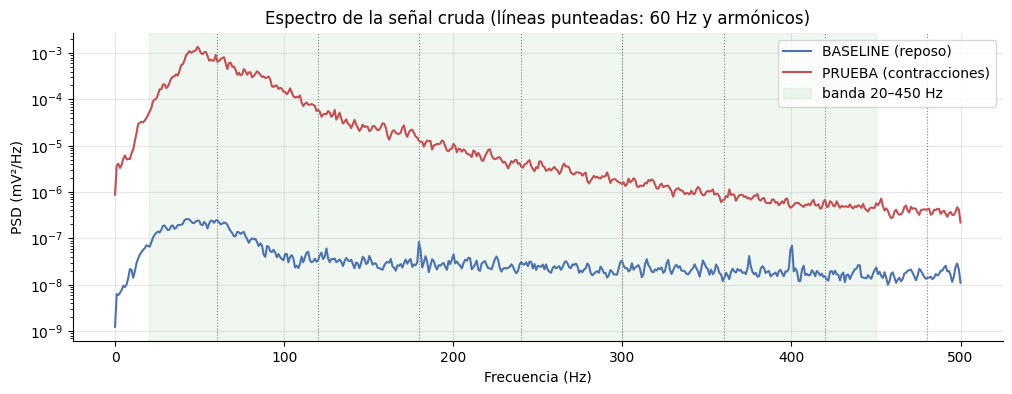

In [ ]:
def psd(x, fs=FS, nperseg=1024):
    return signal.welch(x - np.mean(x), fs=fs, nperseg=nperseg)

f_b, P_b = psd(emg_base_mV)
f_p, P_p = psd(emg_prueba_mV)

plt.figure(figsize=(12, 4))
plt.semilogy(f_b, P_b, label="BASELINE (reposo)", color=COLOR_REPOSO)
plt.semilogy(f_p, P_p, label="PRUEBA (contracciones)", color=COLOR_CONTRAC)
for k in range(1, 9):
    plt.axvline(60*k, color="gray", ls=":", lw=0.8)
plt.axvspan(20, 450, color="green", alpha=0.06, label="banda 20–450 Hz")
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("PSD (mV²/Hz)")
plt.title("Espectro de la señal cruda (líneas punteadas: 60 Hz y armónicos)")
plt.legend(); plt.show()



###**La PSD por el método de Welch (Power Spectral Density)**

La PSD por el método de Welch (Power Spectral Density) permite conocer cómo se distribuye la potencia de una señal entre sus diferentes frecuencias.

¿Cómo funciona?
1. Divide la señal en segmentos solapados.
2. Aplica una ventana a cada segmento para reducir la fuga espectral.
3. Calcula el periodograma de cada segmento mediante la FFT.
4. Promedia los periodogramas para obtener una estimación más estable de la PSD.
¿Para qué sirve en una señal sEMG?

Permite identificar las frecuencias donde se concentra la potencia de la actividad eléctrica muscular y calcular características como la frecuencia media y la frecuencia mediana, útiles para estudiar cambios en la señal, por ejemplo, durante la fatiga muscular.

En resumen: Welch transforma el análisis de una señal en el tiempo en una estimación de su distribución de potencia en frecuencia, reduciendo las fluctuaciones que tendría un único periodograma.

**Explicación.** La PSD por Welch representa la distribución de potencia por frecuencia de la señal cruda. Se comparan el tramo inicial 0–15 s y el registro completo de 291.6 s; no son dos experimentos independientes. Las líneas verticales señalan 60 Hz y sus armónicos, y la franja sombreada marca 20–450 Hz. Las ráfagas de contracción elevan ampliamente la potencia de PRUEBA respecto a BASELINE; la figura por sí sola no permite identificar cada contracción.


**Precaución experimental:** PRUEBA incluye el tramo de referencia de 0–15 s y otros periodos de baja actividad; por ello, su PSD refleja todo el registro y no únicamente contracciones.

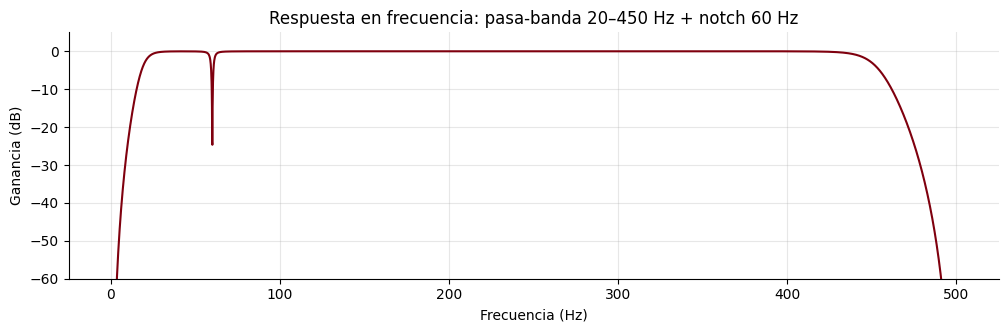

In [ ]:
def filtrar_emg(x, fs=FS, f_baja=20, f_alta=450, orden=4, f_notch=60, q_notch=30):
    if not (0 < f_baja < f_alta < fs/2):
        raise ValueError(f"Se requiere 0 < f_baja < f_alta < Fs/2 (Fs = {fs} Hz).")
    sos = signal.butter(orden, [f_baja, f_alta], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    if f_notch:
        b, a = signal.iirnotch(f_notch, q_notch, fs=fs)
        y = signal.filtfilt(b, a, y)
    return y

# Respuesta en frecuencia de los filtros
sos = signal.butter(4, [20, 450], btype="bandpass", fs=FS, output="sos")
w, h_bp = signal.sosfreqz(sos, worN=4096, fs=FS)
b_n, a_n = signal.iirnotch(60, 30, fs=FS)
_, h_n = signal.freqz(b_n, a_n, worN=4096, fs=FS)
plt.figure(figsize=(12, 3.2))
plt.plot(w, 20*np.log10(np.abs(h_bp*h_n) + 1e-12), color=COLOR_UPCH)
plt.ylim(-60, 5); plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Ganancia (dB)")
plt.title("Respuesta en frecuencia: pasa-banda 20–450 Hz + notch 60 Hz"); plt.show()

emg_base_f   = filtrar_emg(emg_base_mV)
emg_prueba_f = filtrar_emg(emg_prueba_mV)

**Explicación.** El filtro de Butterworth deja pasar aproximadamente **20–450 Hz**, y el *notch* atenúa **60 Hz**. Se aplica filtrado de fase cero (`sosfiltfilt` y `filtfilt`) a BASELINE y PRUEBA. La respuesta en frecuencia del filtro es una propiedad de los parámetros elegidos y no tiene por qué cambiar al usar una nueva grabación.


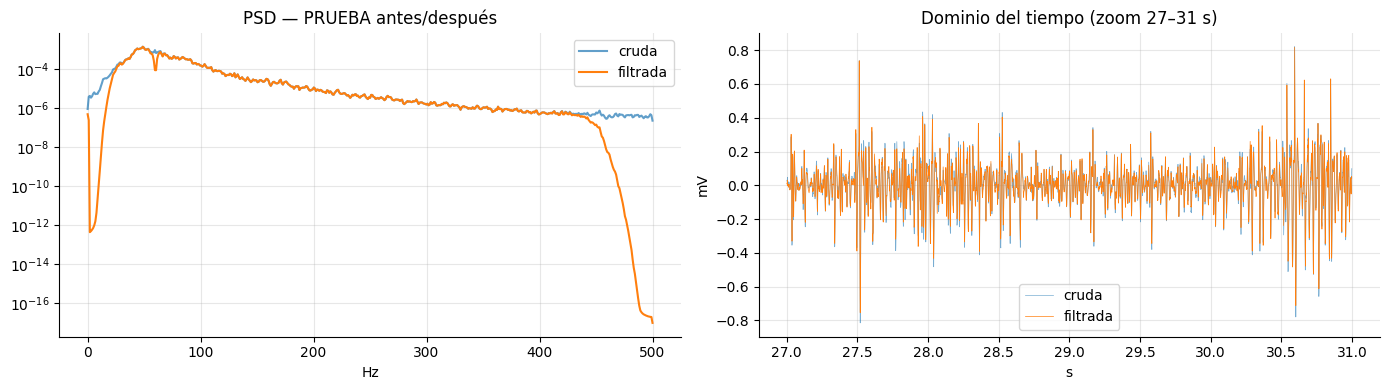

RMS del baseline filtrado (piso de ruido): 4.16 µV
RMS global de la prueba filtrada        : 199.66 µV
SNR aproximada = 20·log10(RMS_prueba / RMS_ruido) = 33.6 dB


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
f1, P1 = psd(emg_prueba_mV); f2, P2 = psd(emg_prueba_f)
ax[0].semilogy(f1, P1, label="cruda", alpha=0.7); ax[0].semilogy(f2, P2, label="filtrada")
ax[0].set_title("PSD — PRUEBA antes/después"); ax[0].set_xlabel("Hz"); ax[0].legend()

sl = (t_prueba > 27) & (t_prueba < 31)
ax[1].plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.5, alpha=0.6, label="cruda")
ax[1].plot(t_prueba[sl], emg_prueba_f[sl], lw=0.5, label="filtrada")
ax[1].set_title("Dominio del tiempo (zoom 27–31 s)"); ax[1].set_xlabel("s"); ax[1].set_ylabel("mV"); ax[1].legend()
plt.tight_layout(); plt.show()

# Estimación simple de la relación señal-ruido usando el baseline como piso de ruido
rms = lambda x: np.sqrt(np.mean(x**2))
p95 = np.percentile(np.abs(emg_prueba_f), 95)
print(f"RMS del baseline filtrado (piso de ruido): {rms(emg_base_f)*1000:.2f} µV")
print(f"RMS global de la prueba filtrada        : {rms(emg_prueba_f)*1000:.2f} µV")
print(f"SNR aproximada = 20·log10(RMS_prueba / RMS_ruido) = "
      f"{20*np.log10(rms(emg_prueba_f)/rms(emg_base_f)):.1f} dB")

**Explicación del antes/después del filtrado.** En la señal real la componente de 60 Hz, respecto a las bandas vecinas, pasó de aproximadamente 1.2 veces a 0.13 veces en PRUEBA (y de 1.2 a 0.10 en BASELINE). El RMS filtrado del tramo inicial fue 4.16 µV y el RMS global de PRUEBA **199.66 µV**; su cociente corresponde a una razón aproximada de 33.6 dB, que no es una SNR rigurosa, pues PRUEBA incluye reposo, actividad muscular y posibles artefactos. La PSD refleja mayor actividad en frecuencias bajas del rango EMG.


🔎 **Verificación adicional — tamaño del pico de 60 Hz y ubicación de la energía de la contracción.**

Para responder con números las preguntas del Bloque 3, la celda siguiente calcula:
1. Cuántas veces es mayor la potencia en 60 Hz que la de sus frecuencias vecinas, antes y después de filtrar.
2. El espectro **solo de los tramos de contracción**, usando el mismo criterio de detección del Bloque 4.

In [ ]:

# Verificación adicional: tamaño del pico de 60 Hz y dónde está la energía de la contracción
def pico_relativo(x, f0=60):
    f, p = signal.welch(x - np.mean(x), fs=FS, nperseg=1024)
    vecinos = p[((f > f0 - 10) & (f < f0 - 3)) | ((f > f0 + 3) & (f < f0 + 10))]
    return p[np.argmin(np.abs(f - f0))] / np.median(vecinos)

for nombre, cruda, filtrada in [("BASELINE", emg_base_mV, emg_base_f), ("PRUEBA", emg_prueba_mV, emg_prueba_f)]:
    print(f"{nombre:8s}: potencia en 60 Hz / potencia de frecuencias vecinas -> "
          f"cruda: {pico_relativo(cruda):6.1f} veces | filtrada: {pico_relativo(filtrada):5.2f} veces")

# Espectro solo de los tramos de contracción (usa la detección del bloque 4; se calcula aquí por adelantado)
env_tmp = np.sqrt(np.convolve(emg_prueba_f**2, np.ones(200)/200, mode="same"))
ref_tmp = env_tmp[env_tmp <= np.percentile(env_tmp, 20)]
activo_tmp = env_tmp > ref_tmp.mean() + 5 * ref_tmp.std()
f_c, P_c = signal.welch(emg_prueba_f[activo_tmp], fs=FS, nperseg=1024)
frac = lambda lo, hi: P_c[(f_c >= lo) & (f_c < hi)].sum() / P_c.sum()
acum = np.cumsum(P_c)
print(f"\nTramos de contracción: pico espectral en {f_c[np.argmax(P_c)]:.0f} Hz | "
      f"frecuencia mediana {f_c[np.searchsorted(acum, acum[-1]/2)]:.0f} Hz")
print(f"Fracción de potencia: 20–150 Hz = {100*frac(20,150):.1f} % | 150–450 Hz = {100*frac(150,451):.1f} % | "
      f"por debajo de 50 Hz = {100*frac(0,50):.1f} %")


BASELINE: potencia en 60 Hz / potencia de frecuencias vecinas -> cruda:    1.2 veces | filtrada:  0.10 veces
PRUEBA  : potencia en 60 Hz / potencia de frecuencias vecinas -> cruda:    1.2 veces | filtrada:  0.13 veces

Tramos de contracción: pico espectral en 49 Hz | frecuencia mediana 57 Hz
Fracción de potencia: 20–150 Hz = 96.5 % | 150–450 Hz = 3.5 % | por debajo de 50 Hz = 37.0 %


> ❓ **Preguntas de verificación**
 > 1. ¿Era visible el pico de 60 Hz en el espectro crudo? ¿Desapareció tras el notch?
 > 2. ¿En qué rango de frecuencias se concentra la energía durante la contracción? ¿Coincide con la teoría?
 > 3. ¿Por qué no se recomienda usar un pasa-bajos de 50 Hz para "limpiar" la sEMG?

**Respuestas con nuestra señal**

1. El pico de 60 Hz no era dominante: su potencia relativa frente a frecuencias vecinas era de aproximadamente 1.2 tanto en BASELINE como en PRUEBA. Tras el notch pasó a 0.10 y 0.13, respectivamente, lo que evidencia una fuerte atenuación; no significa que su potencia sea exactamente cero.
2. Entre los tramos detectados como activos, 96.5 % de la potencia se concentró en 20–150 Hz y 3.5 % en 150–450 Hz; pico ≈49 Hz, MDF ≈57 Hz. La concentración de energía en las frecuencias bajas de la banda EMG es compatible con la teoría de sEMG, aunque la distribución depende del sensor, músculo, filtro y segmentación.
3. Un pasa-bajos de 50 Hz eliminaría gran parte de la información fisiológica por encima de 50 Hz; en esta adquisición el 63 % de potencia estimada no está por debajo de 50 Hz. El protocolo conserva un pasa-banda de 20–450 Hz y un notch específico en 60 Hz para no perder esas componentes.


---
# 4. Segmentación y etiquetado (10 min)

### 4.1 Envolvente y detección de actividad (*onset*)
La **envolvente RMS móvil** resume la amplitud instantánea:

$$
\text{RMS}[n] = \sqrt{\frac{1}{W}\sum_{k=n-W/2}^{n+W/2} x[k]^2}
$$

Un método clásico de detección de *onset* compara la envolvente con un **umbral** derivado del reposo:

$$
\text{umbral} = \mu_{reposo} + k\,\sigma_{reposo}
$$

Probaremos primero tomando el reposo del **archivo BASELINE**.

In [ ]:
def envolvente_rms(x, fs=FS, ventana_ms=200):
    w = max(1, int(fs * ventana_ms / 1000))
    return np.sqrt(np.convolve(x**2, np.ones(w)/w, mode="same"))

env_base   = envolvente_rms(emg_base_f)
env_prueba = envolvente_rms(emg_prueba_f)

K = 5
umbral_baseline = env_base.mean() + K * env_base.std()
print(f"Umbral con el BASELINE: {umbral_baseline*1000:.1f} µV")
print(f"Fracción de la PRUEBA marcada como 'activa': {100*np.mean(env_prueba > umbral_baseline):.1f} %")

Umbral con el BASELINE: 14.3 µV
Fracción de la PRUEBA marcada como 'activa': 32.2 %


**Explicación:** La envolvente RMS de 200 ms permite señalar intervalos activos. Con el umbral calculado del tramo BASELINE (media + 5 desviaciones estándar) se obtiene 14.3 µV, y aproximadamente 32.2 % de las muestras de PRUEBA supera ese umbral. No equivale a 32.2 % de contracciones verdaderas.


### 4.2 Ajuste del umbral con referencia interna
Con el umbral del baseline, una gran parte de la prueba aparece "activa", incluso entre contracciones. Cuando eso ocurre suele deberse a que **el "reposo" dentro de la prueba no es igual al baseline**: el músculo no se relaja del todo entre repeticiones (tono residual), los electrodos se movieron o la impedancia cambió entre registros.

> 💡 **Idea clave:** la referencia de reposo debe tomarse en **las mismas condiciones** que la señal a analizar.

Solución práctica: estimar el reposo **dentro del propio registro**, usando el 20 % de muestras con menor envolvente.

Umbral con reposo intra-registro: 3.6 µV
Contracciones detectadas: 41 | duración media 3.22 ± 6.31 s


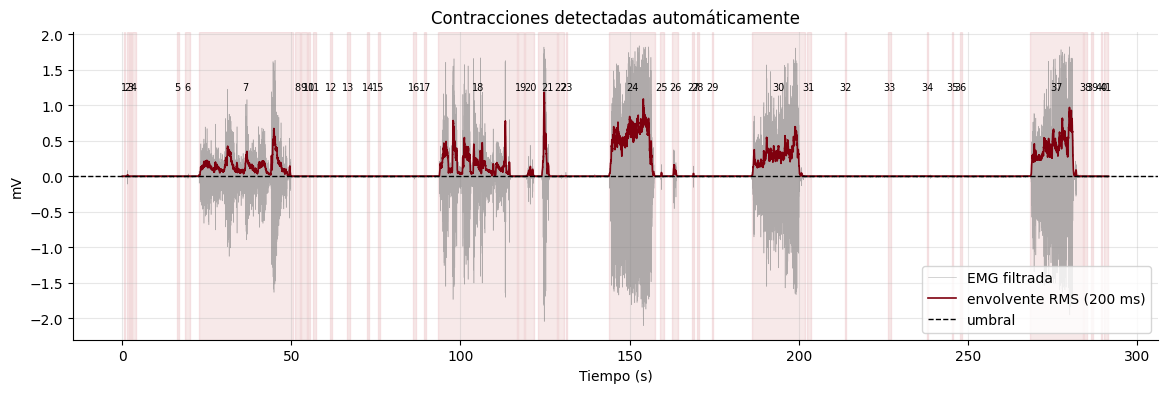

In [ ]:
ref = env_prueba[env_prueba <= np.percentile(env_prueba, 20)]
umbral = ref.mean() + K * ref.std()
print(f"Umbral con reposo intra-registro: {umbral*1000:.1f} µV")

def limpiar_mascara(activo, fs=FS, hueco_min_s=0.25, dur_min_s=0.30):
    # Une segmentos separados por huecos cortos y elimina activaciones demasiado breves
    d = np.diff(np.r_[0, activo.astype(int), 0])
    inicios, fines = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    segs = []
    for s, e in zip(inicios, fines):
        if segs and s - segs[-1][1] < hueco_min_s * fs:
            segs[-1] = (segs[-1][0], e)
        else:
            segs.append((s, e))
    segs = [(s, e) for s, e in segs if (e - s) >= dur_min_s * fs]
    mascara = np.zeros(len(activo), dtype=bool)
    for s, e in segs:
        mascara[s:e] = True
    return mascara, segs

mascara_activa, contracciones = limpiar_mascara(env_prueba > umbral)
dur = np.array([(e - s) / FS for s, e in contracciones])
print(f"Contracciones detectadas: {len(contracciones)} | duración media {dur.mean():.2f} ± {dur.std():.2f} s")

plt.figure(figsize=(14, 4))
plt.plot(t_prueba, emg_prueba_f, lw=0.4, color="gray", alpha=0.6, label="EMG filtrada")
plt.plot(t_prueba, env_prueba, lw=1.2, color=COLOR_UPCH, label="envolvente RMS (200 ms)")
plt.axhline(umbral, color="k", ls="--", lw=1, label="umbral")
for i, (s, e) in enumerate(contracciones):
    plt.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.12)
    plt.text((s+e)/2/FS, env_prueba.max()*1.02, str(i+1), ha="center", fontsize=7)
plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.title("Contracciones detectadas automáticamente")
plt.legend(loc="lower right"); plt.show()

**Explicación:** Al estimar el reposo dentro del registro completo usando el 20 % inferior de la envolvente, el umbral baja a 3.6 µV. El algoritmo identifica 41 intervalos, duración media 3.22 ± 6.31 s. La gran dispersión y varios intervalos con amplitudes cercanas al ruido indican que la máscara probablemente incluye falsos positivos, el número 41 no debe informarse como número confirmado de contracciones voluntarias. Se conservó el procedimiento del laboratorio para poder comparar las salidas.


### 4.3 Ventaneo
Las características se calculan sobre **ventanas** cortas, porque la sEMG es **no estacionaria**: sus propiedades cambian en el tiempo.

| Parámetro | Valor | Compromiso |
|---|---|---|
| Longitud de ventana | 250 ms | Más corta → mejor resolución temporal, pero estimaciones más ruidosas. En control de prótesis se suele trabajar con ventanas de 100–300 ms por la restricción de latencia. |
| Solapamiento | 50 % | Más observaciones, pero **no independientes** entre sí. |

**Etiquetado de cada ventana:**
- `contraccion` si ≥ 80 % de sus muestras están dentro de una contracción detectada.
- `reposo` si ≤ 5 %.
- `transicion` en otro caso (se excluye del entrenamiento: su etiqueta es ambigua).

Además guardamos un **identificador de grupo** (`ciclo`): el reposo previo a la contracción *i* y la propia contracción *i* forman el ciclo *i*. Esto será clave en el Bloque 6 para evitar la **fuga de datos**.

In [ ]:
def crear_ventanas(x, fs=FS, ventana_ms=250, solapamiento=0.5):
    n = int(round(fs * ventana_ms / 1000))
    paso = max(1, int(round(n * (1 - solapamiento))))
    inicios = np.arange(0, len(x) - n + 1, paso)
    return np.stack([x[i:i+n] for i in inicios]), inicios

VENTANA_MS, SOLAP = 250, 0.5
ventanas, inicios = crear_ventanas(emg_prueba_f, FS, VENTANA_MS, SOLAP)
n_win = ventanas.shape[1]

# Etiqueta, ciclo y saturación por ventana
frac_activa = np.array([mascara_activa[i:i+n_win].mean() for i in inicios])
etiqueta = np.where(frac_activa >= 0.8, "contraccion", np.where(frac_activa <= 0.05, "reposo", "transicion"))

inicios_contr = np.array([s for s, _ in contracciones])
ciclo = np.searchsorted(inicios_contr, inicios + n_win // 2, side="right")
ciclo = np.where(etiqueta == "reposo", np.searchsorted(inicios_contr, inicios, side="left"), ciclo - 1)
ciclo = np.clip(ciclo, 0, len(contracciones) - 1)

ventana_saturada = np.array([sat_prueba[i:i+n_win].any() for i in inicios])

print(f"Ventanas: {len(ventanas)} de {n_win} muestras ({VENTANA_MS} ms, solapamiento {int(SOLAP*100)} %)")
print(pd.Series(etiqueta).value_counts().to_string())
print(f"Ventanas con al menos una muestra saturada: {ventana_saturada.sum()}")

Ventanas: 2331 de 250 muestras (250 ms, solapamiento 50 %)
reposo         1200
contraccion    1004
transicion      127
Ventanas con al menos una muestra saturada: 146


**Explicación:** Se generan 2331 ventanas de 250 ms con 50 % de solapamiento, clasificadas mediante la misma máscara automática: 1200 reposo, 1004 contracción y 127 transición. Según el criterio de saturación original (ADC = 0 o 1023), 146 ventanas contienen al menos un extremo. Las etiquetas describen actividad estimada por umbral, no anotaciones externas. El solapamiento hace que ventanas vecinas compartan muestras, y es por ello que no deben dividirse aleatoriamente entre entrenamiento y prueba.


---
# 5. Extracción de características clásicas (25 min)

Una **característica** es una función $f: \mathbb{R}^N \rightarrow \mathbb{R}$ que transforma una ventana de $N$ muestras en un número con significado. Las revisiones sistemáticas sobre reconocimiento de patrones mioeléctricos las agrupan en familias. Trabajaremos con cuatro.

### 5.1 Familia de amplitud / energía
*¿Cuánta actividad hay?* Crecen con el reclutamiento y la frecuencia de disparo.

| Característica | Fórmula | Intuición |
|---|---|---|
| **MAV** (*Mean Absolute Value*) | $\frac{1}{N}\sum_{i=1}^{N}\lvert x_i\rvert$ | Amplitud media rectificada |
| **RMS** (*Root Mean Square*) | $\sqrt{\frac{1}{N}\sum x_i^2}$ | Relacionada con la potencia de la señal |
| **iEMG** (EMG integrada) | $\sum \lvert x_i\rvert$ | Área bajo la señal rectificada |
| **VAR** | $\frac{1}{N-1}\sum (x_i-\bar{x})^2$ | Potencia (la sEMG filtrada tiene media ≈ 0) |

> ⚠️ RMS ≠ fuerza. La relación amplitud-fuerza depende del músculo, es no lineal y requiere normalización (p. ej., respecto de una contracción voluntaria máxima, %MVC) para comparar sujetos o sesiones.

### 5.2 Familia de complejidad / forma de onda
*¿Qué tan rápido y cuánto cambia la señal?* Forman el conjunto clásico propuesto por **Hudgins et al. (1993)** para control de prótesis. Las tres últimas usan un **umbral de ruido** $\varepsilon$ para no contar fluctuaciones del piso de ruido; lo tomaremos del baseline: $\varepsilon = 3\,\sigma_{baseline}$.

| Característica | Definición | Intuición |
|---|---|---|
| **WL** (*Waveform Length*) | $\sum_{i=1}^{N-1}\lvert x_{i+1}-x_i\rvert$ | "Longitud del trazo": combina amplitud y frecuencia |
| **ZC** (*Zero Crossings*) | nº de veces que $x$ cambia de signo con $\lvert x_{i}-x_{i+1}\rvert \ge \varepsilon$ | Estimador temporal de frecuencia |
| **SSC** (*Slope Sign Changes*) | nº de cambios de signo de la pendiente que superan $\varepsilon$ | Densidad de picos |
| **WAMP** (*Willison Amplitude*) | nº de veces que $\lvert x_{i+1}-x_i\rvert > \varepsilon$ | Relacionada con el disparo de unidades motoras |

### 5.3 Familia estadística (forma de la distribución)
*¿Se parecen las amplitudes a una campana de Gauss?*

| Característica | Fórmula | Interpretación |
|---|---|---|
| **Asimetría** (*skewness*) | $\frac{E[(x-\mu)^3]}{\sigma^3}$ | 0 = distribución simétrica |
| **Curtosis de Fisher** | $\frac{E[(x-\mu)^4]}{\sigma^4}-3$ | 0 = gaussiana; > 0 = colas pesadas / picos aislados; < 0 = distribución "aplanada" |

En contracciones con muchas UM, la sEMG tiende a ser cuasi-gaussiana (curtosis cercana a 0). Con pocas UM, o con artefactos, aparecen picos aislados (curtosis alta). La **saturación** recorta las colas y empuja la curtosis hacia valores **negativos**.

### 5.4 Familia espectral
*¿De qué "tonos" está hecha la señal?* A partir de la PSD $P(f)$ por Welch:

| Característica | Fórmula | Interpretación |
|---|---|---|
| **MNF** (frecuencia media) | $\dfrac{\sum f_j P_j}{\sum P_j}$ | Centro de masa del espectro |
| **MDF** (frecuencia mediana) | $f_{med}$ tal que $\sum_{f\le f_{med}} P = \tfrac12 \sum P$ | Divide la potencia en dos mitades; más robusta al ruido |
| **Potencia por bandas** | fracción de potencia en 20–80, 80–150 y 150–450 Hz | Distribución espectral gruesa |

> 💡 **Fatiga muscular:** al fatigarse, disminuye la velocidad de conducción de las fibras y los MUAPs se "ensanchan" → el espectro se desplaza a frecuencias **más bajas** → **MDF y MNF disminuyen**, mientras el RMS suele **aumentar**. Es uno de los indicadores de fatiga más usados.

In [ ]:
EPS = 3 * np.std(emg_base_f)   # umbral de ruido para ZC, SSC y WAMP
print(f"Umbral de ruido ε = {EPS*1000:.1f} µV")

def caracteristicas_temporales(x, eps=EPS):
    dx = np.diff(x)
    zc   = np.sum((x[:-1] * x[1:] < 0) & (np.abs(dx) >= eps))
    ssc  = np.sum(((dx[:-1] * dx[1:]) < 0) & ((np.abs(dx[:-1]) >= eps) | (np.abs(dx[1:]) >= eps)))
    return {
        "MAV":  np.mean(np.abs(x)),
        "RMS":  np.sqrt(np.mean(x**2)),
        "iEMG": np.sum(np.abs(x)),
        "VAR":  np.var(x, ddof=1),
        "WL":   np.sum(np.abs(dx)),
        "ZC":   zc,
        "SSC":  ssc,
        "WAMP": np.sum(np.abs(dx) > eps),
        "Asimetria": skew(x),
        "Curtosis":  kurtosis(x, fisher=True, bias=False),
    }

def caracteristicas_frecuenciales(x, fs=FS):
    f, p = signal.welch(x, fs=fs, nperseg=min(128, len(x)))
    banda = (f >= 20) & (f <= 450)
    f, p = f[banda], p[banda]
    p_tot = p.sum()
    acum = np.cumsum(p)
    pot = lambda lo, hi: p[(f >= lo) & (f < hi)].sum() / p_tot
    return {
        "MNF": np.sum(f * p) / p_tot,
        "MDF": f[np.searchsorted(acum, acum[-1] / 2)],
        "P_20_80":   pot(20, 80),
        "P_80_150":  pot(80, 150),
        "P_150_450": pot(150, 451),
    }

def extraer_caracteristicas(x, fs=FS):
    c = caracteristicas_temporales(x)
    c.update(caracteristicas_frecuenciales(x, fs))
    return c

# Prueba con una sola ventana de cada clase
i_rep = np.flatnonzero(etiqueta == "reposo")[3]
i_con = np.flatnonzero(etiqueta == "contraccion")[3]
display(pd.DataFrame({"reposo": extraer_caracteristicas(ventanas[i_rep]),
                      "contraccion": extraer_caracteristicas(ventanas[i_con])}).round(4))

Umbral de ruido ε = 12.5 µV


,reposo,contraccion
MAV,0.0026,0.0091
RMS,0.0033,0.0198
iEMG,0.6546,2.2629
VAR,0.0000,0.0004
WL,0.8039,1.2101
ZC,0.0000,5.0000
SSC,0.0000,7.0000
WAMP,0.0000,17.0000
Asimetria,0.1097,-1.3314
Curtosis,0.2496,14.2472


**Explicación:** Se implementan las 15 características EMG previstas: MAV, RMS, iEMG, VAR, WL, ZC, SSC, WAMP, asimetría, curtosis, MNF, MDF y proporciones de potencia en tres bandas. El umbral de ruido fijado con BASELINE es ε = 12.5 µV. El ejemplo calculado para una ventana de cada clase muestra, entre otros, RMS de 0.0033 mV en reposo frente a 0.0198 mV en contracción, las diferencias dependen de las ventanas concretas seleccionadas.


In [ ]:
df = pd.DataFrame([extraer_caracteristicas(w) for w in ventanas])
CARACTERISTICAS = list(df.columns)
df.insert(0, "t_inicio_s", inicios / FS)
df["etiqueta"] = etiqueta
df["ciclo"] = ciclo
df["saturada"] = ventana_saturada

print("Matriz de características:", df[CARACTERISTICAS].shape, "(ventanas × características)")
display(df.head())
display(df.groupby("etiqueta")[CARACTERISTICAS].mean().T.round(4))

Matriz de características: (2331, 15) (ventanas × características)


,t_inicio_s,MAV,RMS,iEMG,VAR,WL,ZC,SSC,WAMP,Asimetria,Curtosis,MNF,MDF,P_20_80,P_80_150,P_150_450,etiqueta,ciclo,saturada
0,0.000,0.002912,0.003735,0.727949,0.000014,0.844563,1,2,1,0.452237,0.378722,181.877215,156.2500,0.212992,0.282256,0.504752,reposo,0,False
1,0.125,0.002624,0.003347,0.656008,0.000011,0.810963,2,3,2,0.368131,0.472320,217.400537,203.1250,0.204175,0.203553,0.592272,reposo,0,False
2,0.250,0.002656,0.003405,0.663940,0.000012,0.845182,1,1,1,0.319608,0.000458,206.278091,210.9375,0.207640,0.201078,0.591282,transicion,0,False
3,0.375,0.002968,0.003776,0.741989,0.000014,0.959368,2,3,2,0.238258,-0.183245,211.826100,195.3125,0.218444,0.123320,0.658236,transicion,0,False
4,0.500,0.002912,0.003659,0.727957,0.000013,0.901031,2,3,2,0.255466,-0.190791,203.924573,179.6875,0.165314,0.201832,0.632854,contraccion,0,False


etiqueta,contraccion,reposo,transicion
MAV,0.1575,0.0025,0.0029
RMS,0.2114,0.0033,0.0038
iEMG,39.3852,0.6371,0.7206
VAR,0.0930,0.0000,0.0000
WL,17.2280,0.8135,0.8521
ZC,22.7380,0.7425,1.0157
SSC,35.6145,1.2592,1.5276
WAMP,141.7361,0.7608,1.3858
Asimetria,-0.1806,0.2489,0.2278
Curtosis,2.1134,0.3288,0.6633


**Explicación:** La matriz final tiene **2331 filas y 19 columnas**: 15 características más instante inicial, etiqueta automática, índice de ciclo y marca de saturación. Los promedios de RMS fueron 0.0033 mV en reposo y 0.2114 mV en contracción; los de MNF, 212.30 Hz y *7.81 Hz respectivamente. Esta comparación es interna al registro y depende del umbral de segmentación: no demuestra separación de gestos ni independencia estadística.


### 5.5 Visualización temporal de las características
Observa cómo cada familia "responde" a las contracciones.

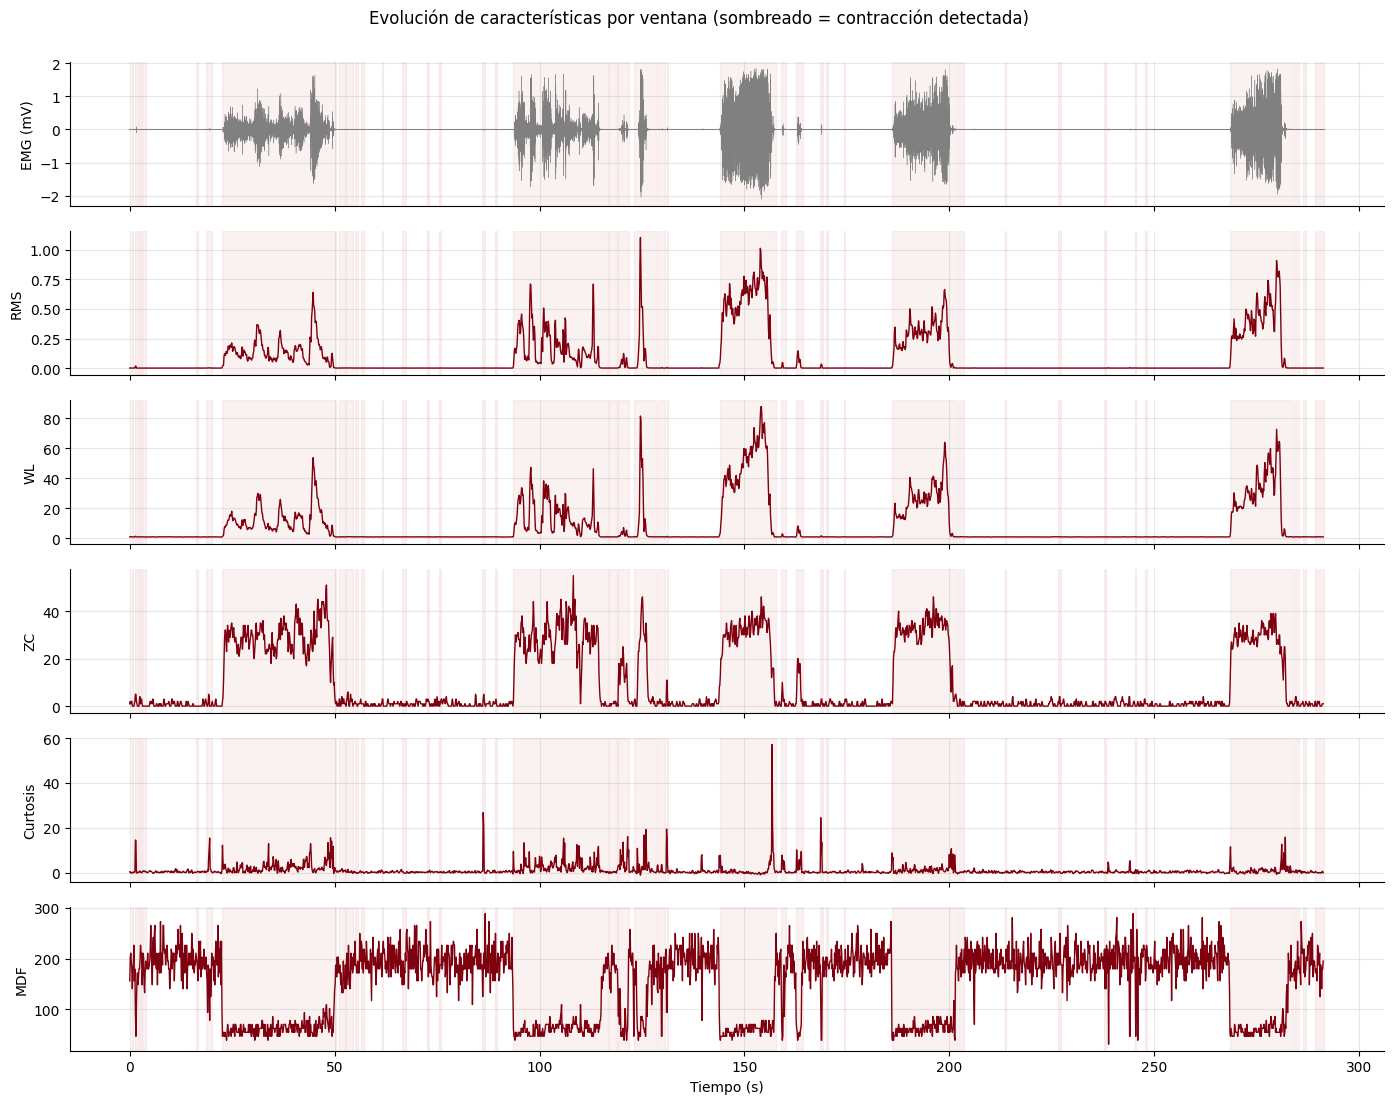

In [ ]:
mostrar = ["RMS", "WL", "ZC", "Curtosis", "MDF"]
fig, ax = plt.subplots(len(mostrar) + 1, 1, figsize=(14, 11), sharex=True)
ax[0].plot(t_prueba, emg_prueba_f, lw=0.3, color="gray")
ax[0].set_ylabel("EMG (mV)")
for a, c in zip(ax[1:], mostrar):
    a.plot(df["t_inicio_s"], df[c], lw=1, color=COLOR_UPCH)
    a.set_ylabel(c)
for a in ax:
    for s, e in contracciones:
        a.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.08)
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("Evolución de características por ventana (sombreado = contracción detectada)", y=1.0)
plt.tight_layout(); plt.show()

**Explicación:** Los gráficos del registro completo permiten observar que RMS y WL aumentan en intervalos de actividad; ZC y MDF también varían, aunque no siempre de forma paralela a la amplitud. La curtosis puede cambiar notablemente en ventanas con picos o recorte. Las líneas se calcularon sobre los 291.6 s de `Fuerte_emg`, no sobre el registro original de ejemplo.


### 5.6 ¿Qué característica separa mejor las clases?
Usaremos dos herramientas:
1. **Boxplots por clase**, para una inspección visual.
2. **Razón de Fisher** para cada característica: $J = \dfrac{(\mu_1-\mu_2)^2}{\sigma_1^2+\sigma_2^2}$. Mide la separación entre medias en relación con la dispersión. Cuanto mayor, más discriminante.

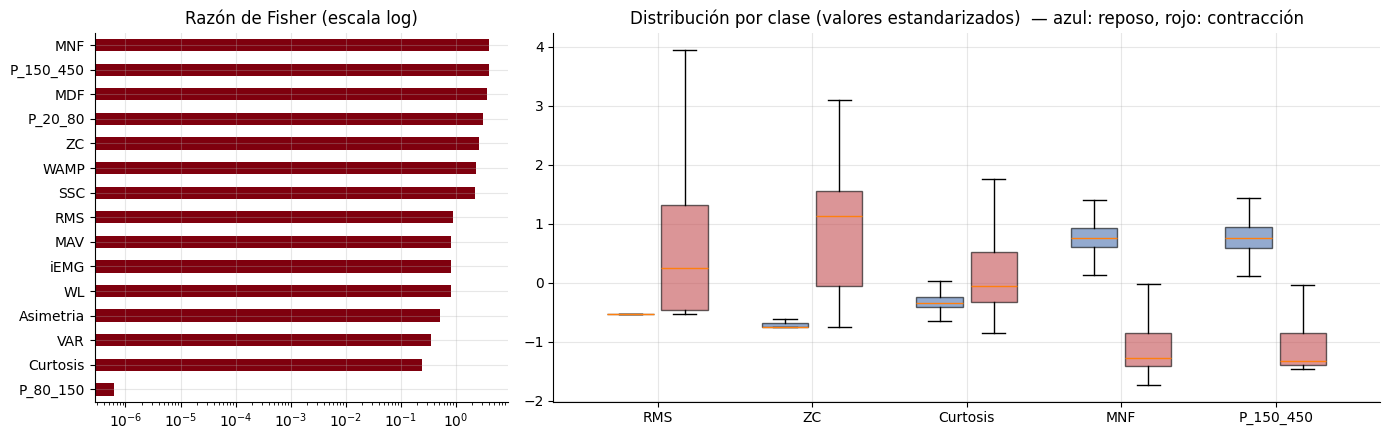

MNF          4.07
P_150_450    4.01
MDF          3.75
P_20_80      3.16
ZC           2.66
WAMP         2.34
SSC          2.28
RMS          0.90
MAV          0.83
iEMG         0.83
WL           0.82
Asimetria    0.53
VAR          0.35
Curtosis     0.24
P_80_150     0.00


In [ ]:
df_ml = df[df["etiqueta"] != "transicion"].copy()
r, c = df_ml[df_ml.etiqueta == "reposo"], df_ml[df_ml.etiqueta == "contraccion"]
fisher = ((r[CARACTERISTICAS].mean() - c[CARACTERISTICAS].mean())**2 /
          (r[CARACTERISTICAS].var() + c[CARACTERISTICAS].var())).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
fisher.plot.barh(ax=ax[0], color=COLOR_UPCH); ax[0].invert_yaxis()
ax[0].set_xscale("log"); ax[0].set_title("Razón de Fisher (escala log)")

seleccion = ["RMS", "ZC", "Curtosis", "MNF", "P_150_450"]
datos_z = (df_ml[seleccion] - df_ml[seleccion].mean()) / df_ml[seleccion].std()
pos = np.arange(len(seleccion))
for k, (lab, col) in enumerate([("reposo", COLOR_REPOSO), ("contraccion", COLOR_CONTRAC)]):
    bp = ax[1].boxplot([datos_z[df_ml.etiqueta == lab][s] for s in seleccion],
                       positions=pos + (k - 0.5) * 0.35, widths=0.3, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(col); b.set_alpha(0.6)
ax[1].set_xticks(pos); ax[1].set_xticklabels(seleccion)
ax[1].set_title("Distribución por clase (valores estandarizados)  — azul: reposo, rojo: contracción")
plt.tight_layout(); plt.show()
print(fisher.round(2).to_string())

**Explicación:** La razón de Fisher calculada en nuestras ventanas de 250 ms fue: MNF = 4.07, P_150_450 = 4.01, MDF = 3.75, P_20_80 = 3.16, ZC = 2.66, WAMP = 2.34 y SSC = 2.28. Las tres primeras son MNF, potencia relativa 150–450 Hz y MDF, a diferencia del registro original, donde predominaban otras características. P_80_150 ≈ 0.00 no separa las clases. La selección refleja diferencias entre etiquetas derivadas de la propia señal y no garantiza generalización.


### 5.7 El efecto de la saturación sobre la curtosis
Comparamos ventanas de contracción **con y sin** muestras saturadas.

RMS       Curtosis       Asimetria           MDF      
           mean count     mean count      mean count    mean count
saturada                                                          
False     0.142   858    2.354   858    -0.173   858  89.853   858
True      0.618   146    0.700   146    -0.226   146  60.306   146

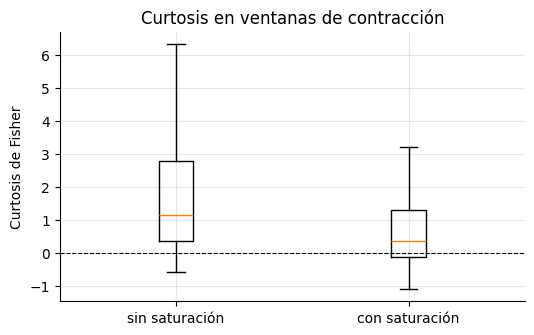

In [ ]:
con = df[df.etiqueta == "contraccion"]
resumen_sat = con.groupby("saturada")[["RMS", "Curtosis", "Asimetria", "MDF"]].agg(["mean", "count"]).round(3)
display(resumen_sat)
if con["saturada"].any():
    plt.figure(figsize=(6, 3.5))
    plt.boxplot([con[~con.saturada]["Curtosis"], con[con.saturada]["Curtosis"]], showfliers=False)
    plt.xticks([1, 2], ["sin saturación", "con saturación"])
    plt.axhline(0, color="k", lw=0.8, ls="--")
    plt.ylabel("Curtosis de Fisher"); plt.title("Curtosis en ventanas de contracción")
    plt.show()

**Explicación: efecto de muestras saturadas.** Entre ventanas etiquetadas como contracción hay 858 sin saturación y 146 con saturación según el criterio original. Sus RMS medios fueron 0.142 y 0.618 mV, respectivamente, y sus curtosis medias 2.354 y 0.700. Las ventanas saturadas concentran actividad de mayor amplitud, pero la disminución de curtosis es una asociación, no una demostración causal aislada. Conviene informar ambos grupos y excluir las ventanas recortadas cuando se estudie la forma de la señal.


🔎 **Verificación adicional — ¿son redundantes las características de amplitud?**

La celda siguiente calcula la correlación entre MAV, RMS, iEMG, VAR y WL. Una correlación de 1 significa que dos características suben y bajan exactamente juntas.

In [ ]:

# Verificación adicional: ¿las características de amplitud son redundantes?
amp = ["MAV", "RMS", "iEMG", "VAR", "WL"]
print("Correlación de Pearson entre características de amplitud (ventanas de reposo y contracción):")
display(df_ml[amp].corr().round(3))


Correlación de Pearson entre características de amplitud (ventanas de reposo y contracción):


,MAV,RMS,iEMG,VAR,WL
MAV,1.000,0.997,1.000,0.944,0.990
RMS,0.997,1.000,0.997,0.933,0.988
iEMG,1.000,0.997,1.000,0.944,0.990
VAR,0.944,0.933,0.944,1.000,0.930
WL,0.990,0.988,0.990,0.930,1.000


> ❓ **Preguntas de verificación**
 > 1. ¿Qué características quedaron arriba en el ranking de Fisher? ZC, SSC y WAMP usan el umbral ε: ¿miden solo "frecuencia" o también amplitud? Justifica.
 > 2. ¿Por qué RMS, MAV, iEMG y VAR obtienen rankings tan parecidos? ¿Aportan información distinta? (Pista: correlación / redundancia).
 > 3. ¿Cómo cambia la curtosis en las ventanas saturadas? ¿Qué harías con esas ventanas en un estudio real?

**Respuestas con nuestra adquisición**

1. Las más discriminantes fueron **MNF (4.07)**, **P_150_450 (4.01)** y **MDF (3.75)**. ZC (**2.66**), WAMP (**2.34**) y SSC (**2.28**) también distinguen clases, pero **dependen tanto del contenido temporal como de la amplitud**, ya que solo cuentan cruces/cambios que superan el umbral **ε = 12.5 µV**. Una señal más intensa puede generar más eventos contados incluso sin cambios en la frecuencia real de disparo.
2. Las variables de amplitud son **redundantes en gran parte**. En nuestros datos, MAV y RMS tienen correlación **0.997**, MAV e iEMG **1.000**, MAV y WL **0.990** y MAV y VAR **0.944**. MAV e iEMG son exactamente proporcionales para ventanas de longitud fija, mientras que VAR eleva las diferencias al cuadrado y no es idéntica a MAV. En modelos multivariables, la selección de características evita redundancias innecesarias.
3. En contracción, la curtosis media fue **2.354** sin saturación y **0.700** con saturación, según ADC = 0/1023. Las ventanas saturadas también tuvieron RMS mayor (**0.618 mV** frente a **0.142 mV**), por lo que recorte e intensidad están mezclados. En un estudio real **marcaría o excluiría ventanas saturadas**, compararía los análisis con y sin ellas y documentaría cuántas se descartan.


---
# 6. Del vector de características al clasificador (15 min)

### 6.1 El flujo clásico de reconocimiento de patrones
```
señal → preprocesamiento → ventanas → [ f1, f2, ..., fK ] → normalización → clasificador → decisión
```

Usaremos:
- **LDA** (*Linear Discriminant Analysis*): muy usado en control mioeléctrico; rápido, robusto y con pocos parámetros.
- **SVM con kernel RBF**: frontera de decisión no lineal.

La **normalización** (*z-score*) se ajusta **solo con los datos de entrenamiento** (por eso usamos un `Pipeline`).

### 6.2 ¡Cuidado con la fuga de datos (*data leakage*)!
Con solapamiento del 50 %, dos ventanas consecutivas **comparten la mitad de sus muestras**. Si una queda en entrenamiento y su vecina en prueba, el modelo "ya vio" parte de la prueba y el desempeño se **sobreestima**.

**Solución:** dividir por **grupos** (ciclos de reposo + contracción) con `GroupKFold`, de modo que ningún ciclo aparezca a la vez en entrenamiento y en prueba.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.model_selection import KFold, GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score

X = df_ml[CARACTERISTICAS].values
y = (df_ml["etiqueta"] == "contraccion").astype(int).values
grupos = df_ml["ciclo"].values

modelos = {
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
}
conjuntos = {
    "Todas las características": CARACTERISTICAS,
    "Solo amplitud (RMS)": ["RMS"],
    "Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)":
        ["Curtosis", "Asimetria", "MNF", "MDF", "P_20_80", "P_80_150", "P_150_450"],
}

cv_grupos = GroupKFold(n_splits=5)
filas = []
for nombre_conj, cols in conjuntos.items():
    Xc = df_ml[cols].values
    for nombre_mod, mod in modelos.items():
        s = cross_val_score(mod, Xc, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
        filas.append({"Características": nombre_conj, "Modelo": nombre_mod,
                      "Exactitud balanceada": f"{s.mean():.3f} ± {s.std():.3f}"})
display(pd.DataFrame(filas))

,Características,Modelo,Exactitud balanceada
0,Todas las características,LDA,0.892 ± 0.028
1,Todas las características,SVM-RBF,0.892 ± 0.030
2,Solo amplitud (RMS),LDA,0.763 ± 0.086
3,Solo amplitud (RMS),SVM-RBF,0.866 ± 0.022
4,"Sin amplitud (Curtosis, Asimetría, MNF, MDF, b...",LDA,0.892 ± 0.028
5,"Sin amplitud (Curtosis, Asimetría, MNF, MDF, b...",SVM-RBF,0.893 ± 0.030


**Explicación del clasificador clásico:** Se usaron **2204 ventanas** sin transición, con `GroupKFold` de 5 pliegues para mantener juntas las ventanas de un mismo grupo/ciclo. Con 15 características, LDA obtuvo 0.892 ± 0.028 y SVM-RBF 0.892 ± 0.030 de exactitud balanceada. Solo con RMS: LDA 0.763 ± 0.086 y SVM-RBF 0.866 ± 0.022. Sin amplitud: LDA 0.892 ± 0.028, SVM 0.893 ± 0.030. No son tasas de acierto sobre gestos anotados independientemente: las etiquetas provienen del mismo registro.


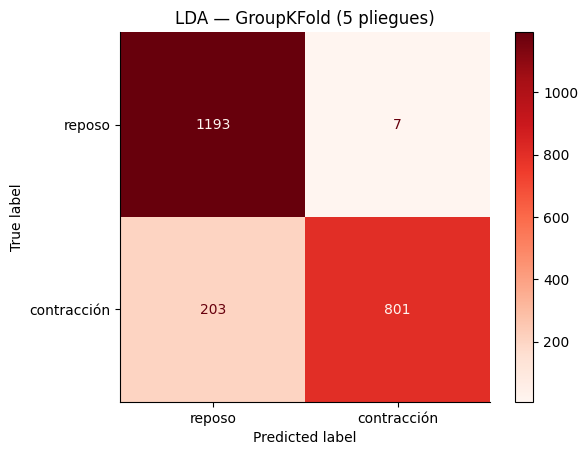

SVM sin amplitud — KFold aleatorio (con fuga): 0.900
SVM sin amplitud — GroupKFold (sin fuga)    : 0.893


In [ ]:
# Matriz de confusión (LDA, todas las características, validación por grupos)
y_pred = cross_val_predict(modelos["LDA"], X, y, cv=cv_grupos, groups=grupos)
ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=["reposo", "contracción"]).plot(cmap="Reds")
plt.title("LDA — GroupKFold (5 pliegues)"); plt.grid(False); plt.show()

# Demostración de la fuga: KFold aleatorio vs GroupKFold con las características SIN amplitud
cols_dificil = conjuntos["Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)"]
Xd = df_ml[cols_dificil].values
mod = modelos["SVM-RBF"]
s_kf = cross_val_score(mod, Xd, y, cv=KFold(5, shuffle=True, random_state=0), scoring="balanced_accuracy")
s_gk = cross_val_score(mod, Xd, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"SVM sin amplitud — KFold aleatorio (con fuga): {s_kf.mean():.3f}")
print(f"SVM sin amplitud — GroupKFold (sin fuga)    : {s_gk.mean():.3f}")

**Explicación.** La matriz de confusión corresponde al LDA con todas las características y validación por grupos. En la comprobación del conjunto sin amplitud, el SVM produjo 0.900 con KFold aleatorio frente a 0.893 con GroupKFold. La diferencia numérica es pequeña en esta ejecución, pero agrupar las ventanas evita mezclar directamente muestras superpuestas o ciclos relacionados entre entrenamiento y evaluación. Esta precaución no elimina el sesgo de etiquetar clases automáticamente con la misma señal.


🔎 **Verificación adicional — para responder las preguntas del Bloque 6.**

La celda siguiente:
- (a) evalúa un clasificador que solo puede aprender **un umbral** sobre el RMS (árbol de decisión de profundidad 1);
- (b) prueba el LDA con **log(RMS)**;
- (c) describe la distribución del RMS en cada clase.

In [ ]:

# Verificación adicional para las preguntas del bloque 6
from sklearn.tree import DecisionTreeClassifier

# (a) ¿Basta un solo umbral en RMS? Un árbol de profundidad 1 aprende exactamente UN umbral
arbol = DecisionTreeClassifier(max_depth=1, random_state=0)
s_umbral = cross_val_score(arbol, df_ml[["RMS"]].values, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"Un solo umbral en RMS (GroupKFold): {s_umbral.mean():.3f} ± {s_umbral.std():.3f}")

# (b) LDA con log(RMS) en lugar de RMS
s_log = cross_val_score(modelos["LDA"], np.log(df_ml[["RMS"]].values), y, cv=cv_grupos, groups=grupos,
                        scoring="balanced_accuracy")
print(f"LDA con RMS     : {cross_val_score(modelos['LDA'], df_ml[['RMS']].values, y, cv=cv_grupos, groups=grupos, scoring='balanced_accuracy').mean():.3f} (tabla anterior)")
print(f"LDA con log(RMS): {s_log.mean():.3f} ± {s_log.std():.3f}")

# (c) Asimetría del RMS en cada clase
for lab in ["reposo", "contraccion"]:
    v = df_ml.loc[df_ml.etiqueta == lab, "RMS"]
    print(f"RMS en {lab:11s}: media {v.mean():.3f} mV | desv. est. {v.std():.3f} mV | asimetría {skew(v):.2f}")


Un solo umbral en RMS (GroupKFold): 0.945 ± 0.009
LDA con RMS     : 0.763 (tabla anterior)
LDA con log(RMS): 0.870 ± 0.023
RMS en reposo     : media 0.003 mV | desv. est. 0.000 mV | asimetría 4.85
RMS en contraccion: media 0.211 mV | desv. est. 0.219 mV | asimetría 1.11


> ❓ **Preguntas de verificación**
 > 1. Reposo vs. contracción es una tarea "fácil": ¿bastaría un umbral en RMS? ¿Para qué sirve, entonces, un vector de muchas características? (Piensa en distinguir **gestos** distintos: flexión, extensión, pinza...).
 > 2. Sin las características de amplitud, ¿sigue habiendo información para separar las clases? ¿Qué te dice eso sobre el contenido espectral de la contracción?
 > 3. Con **solo RMS**, el LDA rinde bastante peor que la SVM. Pista: el LDA supone clases gaussianas con la misma covarianza, y el RMS de la contracción es muy asimétrico y disperso. Prueba con `np.log(RMS)`: ¿qué ocurre?
 > 4. ¿Hubo diferencia entre KFold aleatorio y GroupKFold? Aunque aquí sea pequeña, ¿por qué siempre debemos reportar la validación por grupos/sujetos?

**Respuestas con nuestra señal**

1. Sí, para las **etiquetas generadas automáticamente a partir de la amplitud**, un único umbral RMS consiguió 0.945 ± 0.009, mejor que LDA/SVM con las 15 características (0.892). Un vector de características más amplio cobra importancia para distinguir movimientos distintos, no solo actividad frente a reposo. Este registro carece de etiquetas verificadas de gestos.
2. **Sí.** Sin las características de amplitud, LDA obtuvo 0.892 ± 0.028 y SVM 0.893 ± 0.030. El contenido temporal y espectral separa las etiquetas: por ejemplo, MNF (**4.07**) y potencia relativa 150–450 Hz (4.01) encabezan Fisher. La amplitud no es la única diferencia observada.
3. LDA con RMS crudo obtuvo 0.763 ± 0.086, SVM con RMS 0.866 ± 0.022. Tras transformar RMS con logaritmo, LDA alcanzó 0.870 ± 0.023. La asimetría de RMS (reposo **4.85**, contracción **1.11**) y la dispersión explican por qué una transformación mejora la separación aproximadamente lineal.
4. Para SVM sin amplitud, KFold aleatorio obtuvo 0.900 frente a **0.893** con GroupKFold. La diferencia es pequeña aquí, pero como las ventanas se solapan y comparten episodios, un KFold aleatorio puede introducir fuga por dependencia temporal. La evaluación por grupos reduce ese problema; una evaluación por sujetos independientes requeriría datos de más personas.

**Advertencia metodológica:** como el etiquetado se obtiene de la propia EMG, ninguna de estas exactitudes valida por sí misma la detección independiente de contracciones verdaderas.


---
# 7. Deep learning: del espectrograma a una CNN (15 min)

### 7.1 Características *diseñadas* vs. características *aprendidas*
Hasta ahora **nosotros** decidimos qué calcular (RMS, ZC, MDF...): son características *hand-crafted*, basadas en conocimiento fisiológico. En deep learning, la red **aprende** sus propios filtros a partir de los datos.

| | Clásico (características + LDA/SVM) | Deep learning (CNN) |
|---|---|---|
| Entrada | Vector de ~15 números | Señal cruda (1D-CNN) o imagen tiempo-frecuencia (2D-CNN) |
| Conocimiento experto | Alto (se elige qué medir) | Bajo (la red lo descubre) |
| Datos necesarios | Pocos | Muchos (miles de ventanas, varios sujetos) |
| Interpretabilidad | Alta | Baja |
| Costo computacional | Mínimo | Alto (entrenamiento) |

### 7.2 La Transformada de Fourier de Tiempo Corto (STFT)
La FFT nos dice **qué** frecuencias hay, pero no **cuándo**. La STFT aplica la FFT sobre ventanas deslizantes $w[n]$:

$$
X(m, k) = \sum_{n} x[n]\,w[n - mH]\,e^{-j2\pi kn/N}
$$

El **espectrograma** $|X(m,k)|^2$ es una matriz *tiempo × frecuencia*: **una imagen**. Y las **CNN** son excelentes extrayendo patrones de imágenes.

> 💡 **Principio de incertidumbre tiempo-frecuencia:** una ventana larga da buena resolución en frecuencia y mala en tiempo, y viceversa. Con `nperseg = 64` a 1000 Hz → resolución de 15.6 Hz y 64 ms.

Otras representaciones usadas en la literatura: transformada wavelet continua (escalogramas), transformada de Hilbert-Huang y matrices multicanal en "imagen" (HD-sEMG).

Imágenes: (1048, 27, 29) (muestras, frecuencias, tiempos) | reposo: 566  contracción: 482


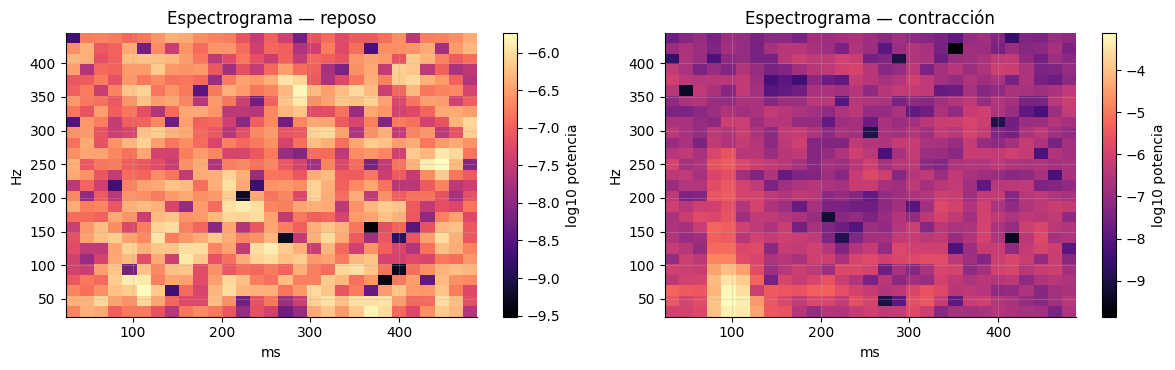

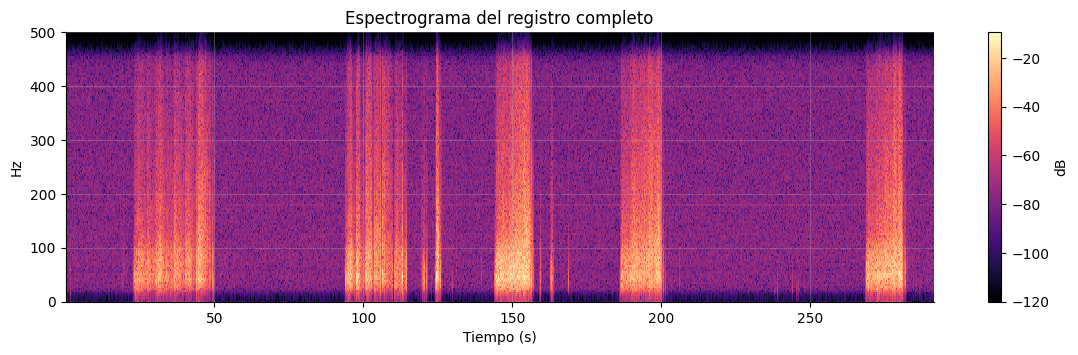

In [ ]:
# Ventanas más largas (500 ms) para que el espectrograma tenga suficientes columnas
VENTANA_CNN_MS = 500
win_cnn, ini_cnn = crear_ventanas(emg_prueba_f, FS, VENTANA_CNN_MS, 0.5)
n_cnn = win_cnn.shape[1]
frac = np.array([mascara_activa[i:i+n_cnn].mean() for i in ini_cnn])
lab_cnn = np.where(frac >= 0.8, 1, np.where(frac <= 0.05, 0, -1))
ciclo_cnn = np.clip(np.where(lab_cnn == 0,
                             np.searchsorted(inicios_contr, ini_cnn, side="left"),
                             np.searchsorted(inicios_contr, ini_cnn + n_cnn//2, side="right") - 1),
                    0, len(contracciones) - 1)
ok = lab_cnn >= 0
win_cnn, lab_cnn, ciclo_cnn = win_cnn[ok], lab_cnn[ok], ciclo_cnn[ok]

def espectrograma(x, fs=FS, nperseg=64, noverlap=48):
    f, t, S = signal.stft(x, fs=fs, nperseg=nperseg, noverlap=noverlap, boundary=None)
    banda = (f >= 20) & (f <= 450)
    return f[banda], t, np.log10(np.abs(S[banda])**2 + 1e-10)

f_s, t_s, _ = espectrograma(win_cnn[0])
imagenes = np.stack([espectrograma(w)[2] for w in win_cnn]).astype(np.float32)
print(f"Imágenes: {imagenes.shape} (muestras, frecuencias, tiempos) | "
      f"reposo: {(lab_cnn==0).sum()}  contracción: {(lab_cnn==1).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, clase, nombre in zip(ax, [0, 1], ["reposo", "contracción"]):
    i = np.flatnonzero(lab_cnn == clase)[2]
    im = a.pcolormesh(t_s*1000, f_s, imagenes[i], shading="auto", cmap="magma")
    a.set_title(f"Espectrograma — {nombre}"); a.set_xlabel("ms"); a.set_ylabel("Hz")
    plt.colorbar(im, ax=a, label="log10 potencia")
plt.tight_layout(); plt.show()

# Espectrograma del registro completo: la "película" tiempo-frecuencia
f_full, t_full, S_full = signal.spectrogram(emg_prueba_f, fs=FS, nperseg=256, noverlap=192)
plt.figure(figsize=(14, 3.5))
plt.pcolormesh(t_full, f_full, 10*np.log10(S_full + 1e-12), shading="auto", cmap="magma")
plt.ylim(0, 500); plt.xlabel("Tiempo (s)"); plt.ylabel("Hz"); plt.colorbar(label="dB")
plt.title("Espectrograma del registro completo"); plt.show()

**Explicación:** Para la CNN se crean ventanas de 500 ms y espectrogramas STFT de 27 × 29 píxeles. Se obtuvieron 1048 imágenes: 566 de reposo y 482 de contracción, según el etiquetado automático. El espectrograma del registro completo permite identificar intervalos brillantes de mayor energía, sin suponer que sean exactamente 20 contracciones ni que todas correspondan a esfuerzos voluntarios.


### 7.3 Arquitectura de la CNN
Una red pequeña (≈ 1 300 parámetros) es suficiente para esta tarea y entrena en segundos en CPU:

```
Entrada (1 × F × T)
 → Conv2D 3×3, 8 filtros  → BatchNorm → ReLU → MaxPool 2×2      ← aprende patrones locales tiempo-frecuencia
 → Conv2D 3×3, 16 filtros → BatchNorm → ReLU → MaxPool 2×2      ← combina patrones en estructuras mayores
 → Global Average Pooling                                         ← resume cada mapa en un número
 → Lineal (16 → 2)                                                ← clasificador
```

Las capas convolucionales hacen el papel de **extractor de características**; la última capa lineal es el **clasificador**. Observa la analogía con el Bloque 6.

Usamos la misma división por grupos que antes para que la comparación sea justa. Cada ciclo entra completo a entrenamiento o a prueba, y la normalización se calcula solo con entrenamiento.

In [ ]:
try:
    import torch
    import torch.nn as nn
    TORCH_OK = True
except ImportError:
    TORCH_OK = False
    print("PyTorch no está disponible. En Colab viene preinstalado; localmente: pip install torch")

if TORCH_OK:
    torch.manual_seed(0)

    class CNNEspectrograma(nn.Module):
        def __init__(self, n_clases=2):
            super().__init__()
            self.extractor = nn.Sequential(
                nn.Conv2d(1, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
                nn.AdaptiveAvgPool2d(1),
            )
            self.clasificador = nn.Linear(16, n_clases)
        def forward(self, x):
            return self.clasificador(self.extractor(x).flatten(1))

    def entrenar_cnn(X_tr, y_tr, X_te, epocas=40, lr=1e-2):
        mu, sd = X_tr.mean(), X_tr.std()
        Xtr = torch.tensor((X_tr - mu) / sd).unsqueeze(1)
        Xte = torch.tensor((X_te - mu) / sd).unsqueeze(1)
        ytr = torch.tensor(y_tr, dtype=torch.long)
        modelo = CNNEspectrograma()
        opt = torch.optim.Adam(modelo.parameters(), lr=lr)
        perdida_fn = nn.CrossEntropyLoss()
        historial = []
        for _ in range(epocas):
            modelo.train()
            perm = torch.randperm(len(Xtr))
            for i in range(0, len(Xtr), 32):
                idx = perm[i:i+32]
                if len(idx) < 2:      # BatchNorm necesita al menos 2 muestras por lote
                    continue
                opt.zero_grad()
                loss = perdida_fn(modelo(Xtr[idx]), ytr[idx])
                loss.backward(); opt.step()
            historial.append(loss.item())
        modelo.eval()
        with torch.no_grad():
            pred = modelo(Xte).argmax(1).numpy()
        return pred, historial, modelo

    print("Parámetros entrenables:",
          sum(p.numel() for p in CNNEspectrograma().parameters() if p.requires_grad))

Parámetros entrenables: 1330


**Explicación:** Se define la CNN pequeña del laboratorio con 1330 parámetros entrenables. Ese número corresponde a la arquitectura, por lo que no cambia al sustituir el registro de entrada con el real, siempre que se mantengan los tamaños y capas especificados.


Pliegue 1: exactitud balanceada = 0.873


Pliegue 2: exactitud balanceada = 0.949


Pliegue 3: exactitud balanceada = 0.953


Pliegue 4: exactitud balanceada = 0.702


Pliegue 5: exactitud balanceada = 0.875

CNN (espectrograma) — GroupKFold: 0.870 ± 0.091


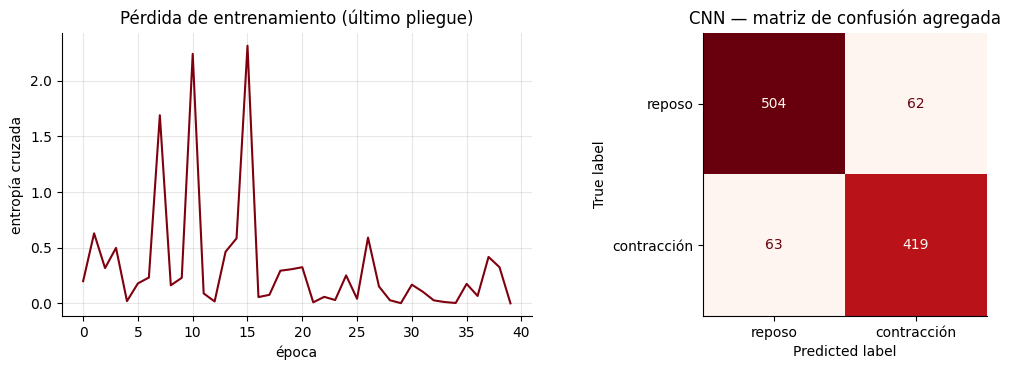

In [ ]:
if TORCH_OK:
    resultados_cnn, y_true_all, y_pred_all = [], [], []
    for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(imagenes, lab_cnn, ciclo_cnn)):
        pred, hist, modelo_cnn = entrenar_cnn(imagenes[tr], lab_cnn[tr], imagenes[te])
        resultados_cnn.append(balanced_accuracy_score(lab_cnn[te], pred))
        y_true_all += list(lab_cnn[te]); y_pred_all += list(pred)
        print(f"Pliegue {k+1}: exactitud balanceada = {resultados_cnn[-1]:.3f}")
    print(f"\nCNN (espectrograma) — GroupKFold: {np.mean(resultados_cnn):.3f} ± {np.std(resultados_cnn):.3f}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist, color=COLOR_UPCH); ax[0].set_title("Pérdida de entrenamiento (último pliegue)")
    ax[0].set_xlabel("época"); ax[0].set_ylabel("entropía cruzada")
    ConfusionMatrixDisplay(confusion_matrix(y_true_all, y_pred_all),
                           display_labels=["reposo", "contracción"]).plot(ax=ax[1], cmap="Reds", colorbar=False)
    ax[1].grid(False); ax[1].set_title("CNN — matriz de confusión agregada")
    plt.tight_layout(); plt.show()

**Explicación:** La CNN se evaluó con **GroupKFold de 5 pliegues**. Las exactitudes balanceadas por pliegue fueron 0.873, 0.949, 0.953, 0.702 y 0.875: media 0.870 ± 0.091. El cuarto pliegue muestra una disminución importante, por lo que el resultado es variable. Con nuestro registro no supera el LDA de 15 características (0.892); además, usa ventanas de 500 ms frente a los 250 ms del LDA, por lo que no es una comparación controlada. Las etiquetas siguen siendo automáticas y provienen de la envolvente EMG.


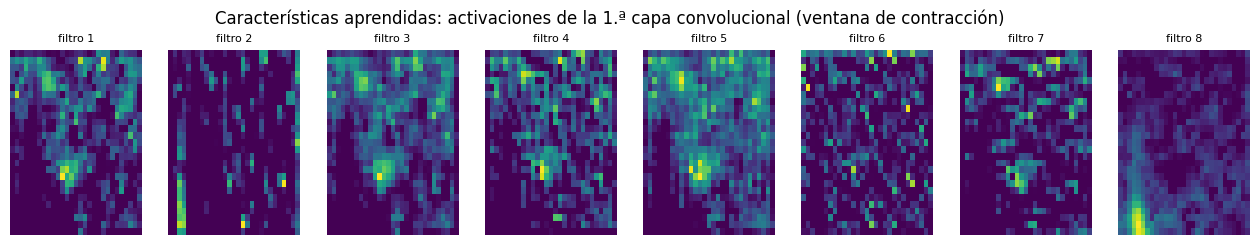

In [ ]:
# ¿Qué "mira" la red? Mapas de activación de los 8 filtros de la primera capa
if TORCH_OK:
    i = np.flatnonzero(lab_cnn == 1)[2]
    x_in = torch.tensor((imagenes[i] - imagenes.mean()) / imagenes.std()).unsqueeze(0).unsqueeze(0)
    with torch.no_grad():
        mapas = modelo_cnn.extractor[:3](x_in)[0].numpy()
    fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
    for k in range(8):
        ax[k].imshow(mapas[k], origin="lower", aspect="auto", cmap="viridis")
        ax[k].set_title(f"filtro {k+1}", fontsize=8); ax[k].axis("off")
    plt.suptitle("Características aprendidas: activaciones de la 1.ª capa convolucional (ventana de contracción)", y=1.05)
    plt.show()

**Explicación.** Los ocho mapas corresponden a las activaciones de filtros de la primera capa convolucional para un espectrograma seleccionado. Muestran distintos patrones espaciales de activación, no unidades motoras detectadas ni frecuencias fisiológicas identificadas automáticamente. La interpretación concreta de cada filtro depende de los pesos aprendidos en esta ejecución y no se debe copiar del entrenamiento con los datos antiguos.


> ❓ **Preguntas de verificación**
 > 1. ¿La CNN superó al LDA con características clásicas? Considerando el costo y la interpretabilidad, ¿cuál elegirías para esta tarea?
 > 2. Aquí tenemos ~200 imágenes de **un solo sujeto**. ¿Qué pasaría con la CNN si probáramos en otra persona?
 > 3. Otra opción es una **1D-CNN** sobre la señal cruda de cada ventana, sin STFT. ¿Qué ventaja y qué desventaja tendría?

✅ **Respuestas con nuestra señal**

1. **No:** la CNN obtuvo 0.870 ± 0.091, el LDA 0.892 ± 0.028 y SVM 0.892 ± 0.030, con todas las características clásicas. Para diferenciar las etiquetas automáticas de reposo/actividad elegiría un umbral RMS (0.945 ± 0.009) por simplicidad e interpretabilidad, con la advertencia de que la etiqueta original también se deriva de amplitud de EMG. La CNN usa ventanas de 500 ms frente a 250 ms en LDA, así que la comparación no está completamente controlada.
2. **No se puede medir ni predecir una caída específica**, porque solo tenemos datos de una adquisición. Diferencias anatómicas, de piel, fuerza y colocación de electrodos podrían reducir el rendimiento. Harían falta adquisiciones de sujetos diferentes y validación dejando sujetos fuera del entrenamiento. En esta ejecución hay 1048 imágenes y no ~200 como en el ejemplo original.
3. **Ventaja de 1D-CNN:** aprende patrones directamente de las muestras sin seleccionar una STFT. **Desventaja:** no recibe explícitamente el mapa tiempo-frecuencia y podría necesitar más datos o un entrenamiento diferente. Solo una comparación experimental con la misma partición permitiría decidir cuál funciona mejor.


---
# 8. Ejercicios

## Ejercicio 1 — Selección de características y tamaño de ventana (obligatorio)
1. Repite la extracción de características con ventanas de **100 ms** y **500 ms** (además de 250 ms).
2. Para cada tamaño, calcula la **razón de Fisher** de RMS, ZC, Curtosis y MDF.
3. Entrena un **LDA con solo las 3 características más discriminantes** (según Fisher) usando `GroupKFold`.
4. Elimina las ventanas saturadas y repite. ¿Cambia el resultado? ¿Cambia la curtosis promedio de la contracción?

**Entrega:** tabla (tamaño de ventana × característica) y una conclusión de 5–8 líneas.

*Completa las líneas marcadas con `# TODO`.*

In [ ]:

# ===== EJERCICIO 1 — SOLUCIÓN =====
def tabla_caracteristicas(x, ventana_ms, solap=0.5):
    w, ini = crear_ventanas(x, FS, ventana_ms, solap)
    n = w.shape[1]
    fr = np.array([mascara_activa[i:i+n].mean() for i in ini])
    et = np.where(fr >= 0.8, "contraccion", np.where(fr <= 0.05, "reposo", "transicion"))
    d = pd.DataFrame([extraer_caracteristicas(v) for v in w])
    d["etiqueta"] = et
    d["ciclo"] = np.clip(np.where(et == "reposo",
                                  np.searchsorted(inicios_contr, ini, side="left"),
                                  np.searchsorted(inicios_contr, ini + n//2, side="right") - 1),
                         0, len(contracciones) - 1)
    d["saturada"] = [sat_prueba[i:i+n].any() for i in ini]
    d["saturada_corr"] = [((adc_prueba[i:i+n] <= 0) | (adc_prueba[i:i+n] >= 2**N_BITS - 2)).any() for i in ini]
    return d[d.etiqueta != "transicion"]

def razon_fisher(d, cols):
    a, b = d[d.etiqueta == "reposo"], d[d.etiqueta == "contraccion"]
    return (a[cols].mean() - b[cols].mean())**2 / (a[cols].var() + b[cols].var())

# Paso 1 y 2: tabla de Fisher por tamaño de ventana
tablas = {vm: tabla_caracteristicas(emg_prueba_f, vm) for vm in [100, 250, 500]}
print("Número de ventanas usadas (sin transiciones):", {f"{k} ms": len(v) for k, v in tablas.items()})
display(pd.DataFrame({f"{vm} ms": razon_fisher(d, ["RMS", "ZC", "Curtosis", "MDF"])
                      for vm, d in tablas.items()}).round(2))

# Paso 3: top-3 por Fisher (250 ms) y LDA con GroupKFold
d250 = tablas[250]
top3 = razon_fisher(d250, CARACTERISTICAS).nlargest(3).index.tolist()
print("Top-3 características (250 ms):", top3)

def evaluar_lda(d, cols):
    yy = (d.etiqueta == "contraccion").astype(int).values
    s = cross_val_score(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
                        d[cols].values, yy, cv=GroupKFold(5), groups=d.ciclo.values, scoring="balanced_accuracy")
    return s.mean(), s.std()

filas = []
for nombre, d in [("Todas las ventanas", d250),
                  ("Sin ventanas saturadas (criterio original)", d250[~d250.saturada]),
                  ("Sin ventanas saturadas (criterio corregido)", d250[~d250.saturada_corr])]:
    m, s = evaluar_lda(d, top3)
    curt = d.loc[d.etiqueta == "contraccion", "Curtosis"].mean()
    filas.append({"Conjunto": nombre, "N ventanas": len(d),
                  "Contracciones": int((d.etiqueta == "contraccion").sum()),
                  "LDA top-3 (exactitud balanceada)": f"{m:.3f} ± {s:.3f}",
                  "Curtosis media en contracción": round(curt, 2)})
display(pd.DataFrame(filas))


Número de ventanas usadas (sin transiciones): {'100 ms': 5713, '250 ms': 2204, '500 ms': 1048}


,100 ms,250 ms,500 ms
RMS,0.77,0.90,1.06
ZC,2.17,2.66,3.21
Curtosis,0.12,0.24,0.31
MDF,2.48,3.75,5.56


Top-3 características (250 ms): ['MNF', 'P_150_450', 'MDF']


,Conjunto,N ventanas,Contracciones,LDA top-3 (exactitud balanceada),Curtosis media en contracción
0,Todas las ventanas,2204,1004,0.889 ± 0.026,2.11
1,Sin ventanas saturadas (criterio original),2058,858,0.864 ± 0.042,2.35
2,Sin ventanas saturadas (criterio corregido),2046,846,0.861 ± 0.046,2.34


✅ **Respuesta — Ejercicio 1 (datos reales `Fuerte_emg (2).txt`)**

**1 y 2. Ventanas y razón de Fisher** (sin ventanas de transición, 50 % de solapamiento):

| Característica | 100 ms (5713 ventanas) | 250 ms (2204) | 500 ms (1048) |
|---|---:|---:|---:|
| RMS | 0.77 | 0.90 | 1.06 |
| ZC | 2.17 | 2.66 | 3.21 |
| Curtosis | 0.12 | 0.24 | 0.31 |
| MDF | 2.48 | 3.75 | 5.56 |

**3. Tres características con mayor Fisher (250 ms):** **MNF**, **P_150_450** y **MDF**. Se evalúan con LDA y validación por grupos.

| Conjunto | Ventanas totales | Ventanas etiquetadas contracción | LDA top-3: exactitud balanceada | Curtosis media, contracción |
|---|---:|---:|---|---:|
| Todas | 2204 | 1004 | 0.889 ± 0.026 | 2.11 |
| Excluyendo saturadas (0/1023) | 2058 | 858 | 0.864 ± 0.042 | 2.35 |
| Excluyendo extremos (0/1022/1023) | 2046 | 846 | 0.861 ± 0.046 | 2.34 |

**4. Discusión:** Al aumentar la ventana de 100 a 500 ms, mejora la razón de Fisher de las cuatro características comparadas; la MDF aumenta de 2.48 a 5.56, pero se pierde resolución temporal y quedan menos ejemplos. La curtosis sigue siendo la menos discriminante de estas cuatro. Excluir ventanas potencialmente recortadas reduce la exactitud balanceada de 0.889 a 0.864/0.861 y aumenta la curtosis media de contracción de 2.11 a aproximadamente 2.34. Esta disminución de exactitud **no demuestra** que las ventanas saturadas mejoren el modelo: también cambia el conjunto de evaluación, eliminando ventanas de mayor amplitud. La evaluación se refiere a etiquetas calculadas automáticamente, no confirmadas externamente.


## Ejercicio 2 — ¿Hay fatiga a lo largo de las contracciones? (tarea)
La teoría predice que con la fatiga **la MDF disminuye** y **el RMS aumenta**.

1. Para cada contracción detectada, calcula RMS, MNF y MDF sobre **toda la contracción**. Descarta 100 ms al inicio y al final para evitar las transiciones.
2. Grafica cada característica en función del número de contracción y ajusta una recta (`np.polyfit`).
3. Calcula la pendiente de la MDF y su correlación de Spearman con el número de contracción (`scipy.stats.spearmanr`).
4. Discute: ¿hay evidencia de fatiga? ¿Qué limitaciones tiene este protocolo para concluirlo? Piensa en la intensidad no controlada, en pocas repeticiones y en la saturación.

Opcional, para quien quiera profundizar en deep learning: entrena la CNN del Bloque 7 con ventanas de 250 ms y compara.

Contracciones analizadas: 31 | duración del registro: 291.60 s


,contraccion,inicio_s,fin_s,RMS,MNF,MDF
0,2,1.34,1.90,0.017,58.391,46.875
1,4,2.93,3.96,0.004,193.106,164.062
2,5,16.07,16.68,0.004,192.304,203.125
3,6,18.64,19.95,0.004,164.515,125.000
4,7,22.57,50.35,0.183,69.065,54.688
5,8,51.13,52.53,0.004,181.346,156.250
6,9,52.79,54.53,0.004,195.467,179.688
7,10,55.00,55.64,0.004,207.658,187.500
8,11,56.40,57.16,0.003,215.810,218.750
9,13,66.53,67.30,0.003,198.832,171.875


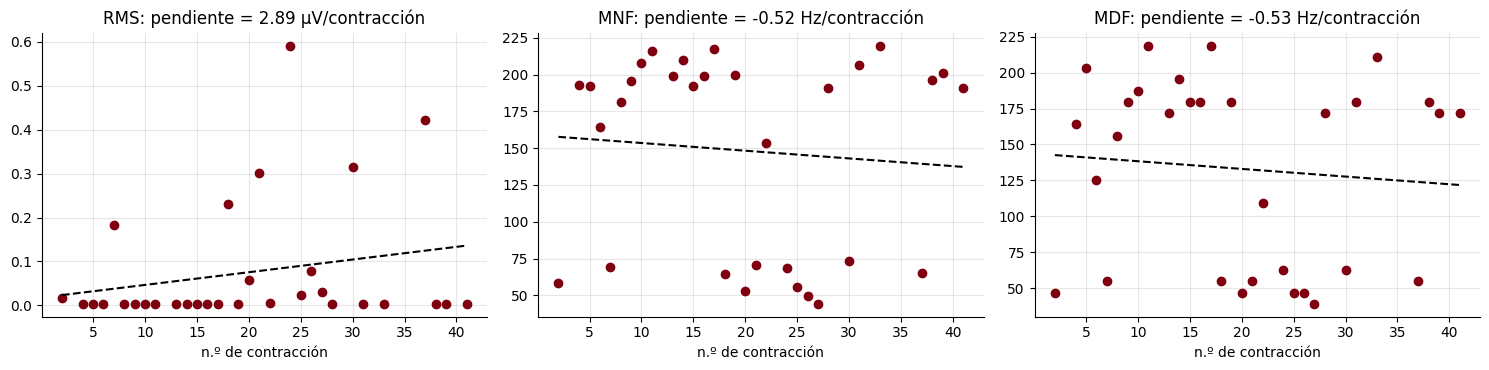

Con todas las contracciones:


,Característica,Pendiente,rho de Spearman,p-valor
0,RMS,2.89 µV/contr.,0.15,0.408
1,MNF,-0.52 Hz/contr.,-0.06,0.735
2,MDF,-0.53 Hz/contr.,-0.12,0.536


Sin la última contracción:


,Característica,Pendiente,rho de Spearman,p-valor
0,RMS,3.77 µV/contr.,0.20,0.283
1,MNF,-0.88 Hz/contr.,-0.06,0.753
2,MDF,-0.87 Hz/contr.,-0.14,0.471


In [ ]:

# ===== EJERCICIO 2 — SOLUCIÓN =====
from scipy.stats import spearmanr

MARGEN = int(0.1 * FS)
filas = []
for k, (s, e) in enumerate(contracciones):
    seg = emg_prueba_f[s + MARGEN : e - MARGEN]
    if len(seg) < 0.3 * FS:
        continue
    c = extraer_caracteristicas(seg)
    filas.append({"contraccion": k + 1, "inicio_s": round(s/FS, 2), "fin_s": round(e/FS, 2),
                  "RMS": c["RMS"], "MNF": c["MNF"], "MDF": c["MDF"]})
df_fatiga = pd.DataFrame(filas)
print(f"Contracciones analizadas: {len(df_fatiga)} | duración del registro: {len(emg_prueba_f)/FS:.2f} s")
display(df_fatiga.round(3))

unidades = {"RMS": ("µV", 1000), "MNF": ("Hz", 1), "MDF": ("Hz", 1)}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
resumen = []
for a, nombre in zip(ax, ["RMS", "MNF", "MDF"]):
    xk, yk = df_fatiga["contraccion"], df_fatiga[nombre]
    pend, inter = np.polyfit(xk, yk, 1)
    rho, p = spearmanr(xk, yk)
    u, esc = unidades[nombre]
    a.plot(xk, yk, "o", color=COLOR_UPCH); a.plot(xk, pend*xk + inter, "k--")
    a.set_title(f"{nombre}: pendiente = {pend*esc:.2f} {u}/contracción"); a.set_xlabel("n.º de contracción")
    resumen.append({"Característica": nombre, f"Pendiente": f"{pend*esc:.2f} {u}/contr.",
                    "rho de Spearman": round(rho, 2), "p-valor": round(p, 3)})
plt.tight_layout(); plt.show()
print("Con todas las contracciones:"); display(pd.DataFrame(resumen))

# Sensibilidad: repetir sin la última contracción (comprobar en la tabla si termina junto con el registro)
d2 = df_fatiga.iloc[:-1]
res2 = []
for nombre in ["RMS", "MNF", "MDF"]:
    pend = np.polyfit(d2["contraccion"], d2[nombre], 1)[0]
    rho, p = spearmanr(d2["contraccion"], d2[nombre])
    u, esc = unidades[nombre]
    res2.append({"Característica": nombre, "Pendiente": f"{pend*esc:.2f} {u}/contr.",
                 "rho de Spearman": round(rho, 2), "p-valor": round(p, 3)})
print("Sin la última contracción:"); display(pd.DataFrame(res2))


**Respuesta — Ejercicio 2 (registro real)**

El procedimiento original detectó 41 intervalos, pero solo 31 cumplieron el requisito mínimo de duración tras descartar 100 ms al inicio y al final. Algunos intervalos etiquetados como contracción presentan RMS ≈0.003–0.004 mV, cercanos al ruido, por lo que no pueden considerarse contracciones musculares voluntarias confirmadas.

**Resultados para los 31 intervalos analizados:**

| Característica | Pendiente por contracción | ρ de Spearman | p-valor |
|---|---:|---:|---:|
| RMS | +2.89 µV | +0.15 | 0.408 |
| MNF | −0.52 Hz | −0.06 | 0.735 |
| MDF | −0.53 Hz | −0.12 | 0.536 |

**Análisis de sensibilidad sin el último intervalo:** RMS +3.77 µV (ρ = 0.20; p = 0.283); MNF −0.88 Hz (ρ = −0.06; p = 0.753); MDF −0.87 Hz (ρ = −0.14; p = 0.471).

**¿Hay evidencia de fatiga?** No hay evidencia estadística suficiente de una tendencia consistente en las características medidas (todos los p-valores son mayores de 0.05); esto no demuestra ausencia fisiológica de fatiga.

**Limitaciones:** No se documentó fuerza controlada ni marcadores de contracción voluntaria, la segmentación detecta también intervalos de amplitud mínima, existe recorte en algunas activaciones, los intervalos son de duración muy desigual y la frecuencia espectral depende de la resolución de Welch. Para estudiar fatiga con mayor fundamento se necesitarían contracciones sostenidas con intensidad conocida, tiempos marcados y un análisis por contracciones verdaderas, idealmente con sujetos adicionales.


**Relación con el protocolo:** la hipótesis de fatiga requiere contracciones comparables y voluntarias confirmadas. Aquí solo existe segmentación automática a partir de amplitud, de modo que la conclusión se limita a tendencias exploratorias.

---
# 9. Cierre y síntesis

### Lo que hicimos
| Etapa | Concepto clave |
|---|---|
| Fisiología | La sEMG es la suma de MUAPs; amplitud y espectro reflejan el reclutamiento y la frecuencia de disparo |
| Adquisición | Amplificación diferencial, Fs ≥ 2·f_max, conversión ADC → mV, **la saturación no se repara** |
| Preprocesamiento | Pasa-banda 20–450 Hz + notch 60 Hz, filtrado de fase cero |
| Segmentación | Envolvente RMS, umbral con reposo **en las mismas condiciones**, ventanas de 100–500 ms |
| Características | Amplitud (RMS, MAV), complejidad (WL, ZC, SSC, WAMP), estadísticas (curtosis, asimetría), espectrales (MNF, MDF) |
| Clasificación | Normalización dentro del pipeline, **validación por grupos** para evitar fuga |
| Deep learning | STFT → espectrograma → CNN que **aprende** sus características |

### Para pensar
- ¿Qué características usarías para una prótesis que debe decidir en menos de 300 ms?
- ¿Cómo cambiaría el análisis con **varios canales** (varios músculos) en lugar de uno?
- ¿Qué haría falta para que el modelo funcione en **otro sujeto**?

### Entregables
1. Este cuaderno ejecutado, con las preguntas de verificación respondidas en celdas de texto.
2. Ejercicio 1 completo (tabla y conclusión).
3. Ejercicio 2 (gráficas de RMS, MNF y MDF con su interpretación).
4. Archivo `caracteristicas_emg.csv` (se genera en la celda siguiente).

### Referencias recomendadas
- De Luca, C. J. (1997). *The use of surface electromyography in biomechanics.* Journal of Applied Biomechanics, 13(2), 135–163.
- Hermens, H. J., Freriks, B., Disselhorst-Klug, C., & Rau, G. (2000). *Development of recommendations for SEMG sensors and sensor placement procedures (SENIAM).* Journal of Electromyography and Kinesiology, 10(5), 361–374.
- Hudgins, B., Parker, P., & Scott, R. N. (1993). *A new strategy for multifunction myoelectric control.* IEEE Transactions on Biomedical Engineering, 40(1), 82–94.
- Phinyomark, A., Phukpattaranont, P., & Limsakul, C. (2012). *Feature reduction and selection for EMG signal classification.* Expert Systems with Applications, 39(8), 7420–7431.
- Atzori, M., Cognolato, M., & Müller, H. (2016). *Deep learning with convolutional neural networks applied to electromyography data: a resource for the classification of movements for prosthetic hands.* Frontiers in Neurorobotics, 10, 9.
- PLUX. *BITalino (r)evolution — EMG Sensor Datasheet* (fórmula de conversión de unidades).

✅ **Respuestas a «Para pensar»**

- **¿Qué usarías en una prótesis que debe decidir en menos de 300 ms?** Usaría entanas de 100–250 ms con características de cálculo rápido: RMS, MAV, WL, ZC, SSC o WAMP. Aquí, con 100 ms, Fisher fue 0.77 en RMS, 2.17 en ZC, 0.12 en curtosis y 2.48 en MDF; una medida espectral puede separar clases, pero puede ser menos estable y más costosa. Hay que contabilizar también el tiempo de adquisición de la ventana y el procesamiento.
- **¿Cómo cambia con varios canales?** Se extraen características por músculo/canal y se concatenan en un vector, se puede reconocer patrones espaciales de activación y no solo actividad en un único músculo. La sincronización y la ubicación de los electrodos son esenciales.
- **¿Qué hace falta para otra persona?** Adquirir señales de múltiples sujetos y condiciones, controlar colocación, amplitud y fuerza, normalizar por sujeto cuando sea pertinente y validar con sujetos excluidos totalmente del entrenamiento. Con un solo registro y etiquetas derivadas de su amplitud, no puede demostrarse generalización intersujeto.


In [ ]:
df.to_csv("caracteristicas_emg.csv", index=False)
print("Archivo generado: caracteristicas_emg.csv", df.shape)
if EN_COLAB:
    from google.colab import files
    files.download("caracteristicas_emg.csv")

Archivo generado: caracteristicas_emg.csv (2331, 19)


**Explicación:** Se guardó `caracteristicas_emg.csv` con 2331 filas × 19 columnas: 15 características y las columnas de inicio de ventana, etiqueta automática, ciclo y saturación. Se obtuvo directamente de `Fuerte_emg (2).txt`. Para conservar la procedencia, las etiquetas deben describirse como derivadas de la señal, no como anotaciones manuales de movimientos.
